# 03 – Santé

**Développeur 3 :** Fejzullahu Irfat  
**Projet :** UE Data Mining 2026-2027 – section santé.

**Fichiers chargés :** `patient_administration.csv`, `clinical_encounters.csv`, `clinical_observations.csv`, `clinical_procedures.csv`, `licensed_facilities.csv`, `public_appointments.csv`, `cardiac_recordings.csv`, `cardiac_signal_samples.csv`, `clinical_notes.csv`, `officer_filings.csv`.

**Clés utilisées :** `patient_number` pour les patients et `encounter_number` pour les consultations.

Les données sont fictives. Une valeur étrange doit être vérifiée avant d'être interprétée.

## 0. Chargement des données

In [1]:
from pathlib import Path

import pandas as pd

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)

DATA = Path("data")

FILES = {
    "patients": "health/patient_administration.csv",
    "encounters": "health/clinical_encounters.csv",
    "observations": "health/clinical_observations.csv",
    "procedures": "health/clinical_procedures.csv",
}

# tout lire en texte pour faire les conversions plus tard
raw = {}
for name in FILES:
    raw[name] = pd.read_csv(
        DATA / FILES[name], dtype=str, keep_default_na=False, na_values=[""]
    )

# premier apercu de la taille de chaque fichier
overview = []
for name in raw:
    df = raw[name]
    overview.append({
        "table": name,
        "lignes": len(df),
        "colonnes": df.shape[1],
        "cellules vides": int(df.isna().sum().sum())
    })
pd.DataFrame(overview).set_index("table")

,lignes,colonnes,cellules vides
table,,,
patients,241,10,0
encounters,1069,12,240
observations,17736,14,23878
procedures,311,14,316


## 1. Découvrir et nettoyer les données de santé

On commence par vérifier les identifiants. Les dates et les valeurs manquantes seront traitées ensuite.

In [2]:
PRIMARY_KEYS = {
    "patients": "patient_number",
    "encounters": "encounter_number",
    "observations": "observation_number",
    "procedures": "procedure_record_id",
}

# compter les identifiants differents et ceux qui reviennent plusieurs fois
rows = []
for name in PRIMARY_KEYS:
    df = raw[name]
    key = PRIMARY_KEYS[name]
    counts = df[key].value_counts()
    rows.append({
        "table": name,
        "lignes": len(df),
        "clé": key,
        "identifiants distincts": df[key].nunique(),
        "identifiants manquants": int(df[key].isna().sum()),
        "identifiants répétés": int((counts > 1).sum())
    })
pd.DataFrame(rows).set_index("table")

,lignes,clé,identifiants distincts,identifiants manquants,identifiants répétés
table,,,,,
patients,241,patient_number,240,0,1
encounters,1069,encounter_number,1067,0,2
observations,17736,observation_number,17734,0,2
procedures,311,procedure_record_id,310,0,1


**Premier constat.** Le fichier patients contient **241 lignes pour 240 identifiants différents**. Il faut comparer les lignes du patient répété avant de choisir quoi garder.

Il y a aussi 2 identifiants répétés dans les rencontres, 2 dans les observations et 1 dans les procédures. Aucun identifiant principal n'est manquant.

### 1.1 Doublons

On vérifie si les lignes avec le même identifiant sont identiques ou différentes.

In [3]:
rows = []
for name in PRIMARY_KEYS:
    df = raw[name]
    key = PRIMARY_KEYS[name]
    repeated_ids = df.loc[df[key].duplicated(keep=False), key].drop_duplicates()

    # retirer les copies identiques pour voir s'il reste des differences
    unique_rows = df.drop_duplicates()
    rows.append({
        "table": name,
        "identifiants concernés": ", ".join(repeated_ids),
        "copies identiques": int(df.duplicated().sum()),
        "identifiants encore répétés sans les copies": int(unique_rows[key].duplicated().sum())
    })
pd.DataFrame(rows).set_index("table")

,identifiants concernés,copies identiques,identifiants encore répétés sans les copies
table,,,
patients,PAT-31045,1,0
encounters,"ENC-000733, ENC-000846",2,0
observations,"OBS-0003236, OBS-0015195",2,0
procedures,PRC-000263,1,0


Exemple avec le patient présent deux fois :

In [4]:
df = raw["patients"]
df[df["patient_number"].duplicated(keep=False)]

,patient_number,family_name,given_name,date_of_birth,registered_sex,home_region,occupation_text,registration_date,primary_facility_license,record_status
173,PAT-31045,Garen,Olia,2000-08-01,female,Nordhaven Union,transport worker,2021-02-01,FAC-VLN-101,active
240,PAT-31045,Garen,Olia,2000-08-01,female,Nordhaven Union,transport worker,2021-02-01,FAC-VLN-101,active


Les lignes répétées sont identiques dans les quatre fichiers. On garde un seul exemplaire de chaque ligne pour éviter de compter deux fois les mêmes données.

In [5]:
# garder les tables d'origine dans raw et les tables nettoyees dans clean
clean = {}
rows = []
for name in raw:
    df = raw[name]
    clean[name] = df.drop_duplicates().reset_index(drop=True)
    key = PRIMARY_KEYS[name]
    rows.append({
        "table": name,
        "lignes avant": len(df),
        "copies supprimées": len(df) - len(clean[name]),
        "lignes après": len(clean[name]),
        "clé unique": clean[name][key].is_unique
    })
pd.DataFrame(rows).set_index("table")

,lignes avant,copies supprimées,lignes après,clé unique
table,,,,
patients,241,1,240,True
encounters,1069,2,1067,True
observations,17736,2,17734,True
procedures,311,1,310,True


Après retrait des copies, il reste **240 patients, 1 067 rencontres, 17 734 observations et 310 procédures**. Les identifiants principaux sont maintenant uniques dans chaque table.

### 1.2 Dates

Plusieurs formats sont utilisés. On les convertit en dates pandas pour pouvoir les comparer.
Une date comme `01/09/2019` est lue comme le 1er septembre 2019.

Les valeurs `null` et `NA` sont considérées comme manquantes.

In [6]:
DATE_COLUMNS = {
    "patients": ["date_of_birth", "registration_date"],
    "encounters": ["encounter_start", "encounter_end", "follow_up_date"],
    "observations": ["observation_time"],
    "procedures": ["scheduled_time", "performed_time", "next_review_date"],
}

rows = []
for name in DATE_COLUMNS:
    for col in DATE_COLUMNS[name]:
        original = clean[name][col].astype("string")
        missing_codes = original.isin(["null", "NA"])
        values = original.replace(["null", "NA"], pd.NA)
        non_iso = values.notna() & ~values.str.match(r"^\d{4}-\d{2}-\d{2}", na=False)

        converted = pd.to_datetime(values, format="mixed", dayfirst=True, errors="coerce")
        failed = values.notna() & converted.isna()
        clean[name][col] = converted

        rows.append({
            "table": name,
            "colonne": col,
            "autres formats": int(non_iso.sum()),
            "codes manquants": int(missing_codes.sum()),
            "échecs de conversion": int(failed.sum())
        })
        if failed.any():
            print(name, col, "dates non lues :", original[failed].tolist())

date_report = pd.DataFrame(rows)
date_report

,table,colonne,autres formats,codes manquants,échecs de conversion
0,patients,date_of_birth,0,0,0
1,patients,registration_date,2,0,0
2,encounters,encounter_start,4,0,0
3,encounters,encounter_end,4,0,0
4,encounters,follow_up_date,2,3,0
5,observations,observation_time,0,0,0
6,procedures,scheduled_time,2,0,0
7,procedures,performed_time,1,0,0
8,procedures,next_review_date,0,0,0


**Résultat.** 15 dates étaient écrites dans un autre format. Toutes les dates renseignées ont pu être converties.
Les 3 codes manquants concernent la date de suivi des consultations. On ne leur invente pas de date.

On vérifie ensuite que l'inscription ne précède pas la naissance et que la fin d'une consultation ne précède pas son début. Seules les lignes avec les deux dates sont comparées.

In [7]:
DATE_CHECKS = {
    "patients": ("date_of_birth", "registration_date"),
    "encounters": ("encounter_start", "encounter_end"),
}

rows = []
for name in DATE_CHECKS:
    start, end = DATE_CHECKS[name]
    df = clean[name]
    comparable = df[start].notna() & df[end].notna()
    bad = comparable & (df[end] < df[start])
    rows.append({
        "table": name,
        "début": start,
        "fin": end,
        "lignes comparées": int(comparable.sum()),
        "fin avant début": int(bad.sum())
    })
    if bad.any():
        print(df.loc[bad, [PRIMARY_KEYS[name], start, end]].to_string(index=False))

pd.DataFrame(rows).set_index("table")

,début,fin,lignes comparées,fin avant début
table,,,,
patients,date_of_birth,registration_date,240,0
encounters,encounter_start,encounter_end,1067,0


Aucune inscription avant la naissance et aucune fin de consultation avant son début sur les 240 patients et les 1 067 consultations.

### 1.3 Valeurs manquantes

On remplace les codes `null`, `NA` et `N/A` par des valeurs manquantes dans les champs concernés.
Le mot `none` est conservé : il peut indiquer une absence de problème constaté.

On garde les lignes et les absences de données : une absence peut aussi être une information.

In [8]:
MISSING_COLUMNS = {
    "observations": ["text_value", "device_reference"],
    "procedures": ["material_reference"],
}

rows = []
for name in MISSING_COLUMNS:
    for col in MISSING_COLUMNS[name]:
        missing_codes = clean[name][col].isin(["null", "NA", "N/A"])
        clean[name].loc[missing_codes, col] = pd.NA
        rows.append({
            "table": name,
            "colonne": col,
            "codes remplacés": int(missing_codes.sum())
        })
pd.DataFrame(rows)

,table,colonne,codes remplacés
0,observations,text_value,35
1,observations,device_reference,20
2,procedures,material_reference,1


In [9]:
# compter les valeurs manquantes apres les conversions
missing = []
for name in clean:
    df = clean[name]
    for col in df.columns:
        count = int(df[col].isna().sum())
        if count > 0:
            missing.append({
                "table": name,
                "colonne": col,
                "manquants": count,
                "%": round(100 * count / len(df), 1)
            })

missing_report = pd.DataFrame(missing)
missing_report

,table,colonne,manquants,%
0,encounters,referral_source,3,0.3
1,encounters,follow_up_date,240,22.5
2,observations,numeric_value,1870,10.5
3,observations,text_value,15864,89.5
4,observations,unit,1870,10.5
5,observations,device_reference,4325,24.4
6,procedures,material_reference,260,83.9
7,procedures,next_review_date,56,18.1


Dans les observations, le résultat peut être un chiffre ou du texte. On vérifie qu'au moins un des deux champs est renseigné, et que les valeurs chiffrées ont une unité.

In [10]:
observations = clean["observations"]
has_number = observations["numeric_value"].notna()
has_text = observations["text_value"].notna()

pd.DataFrame({
    "contrôle": [
        "Champ numeric_value renseigné",
        "Champ text_value renseigné",
        "Ni chiffre ni texte",
        "Chiffre renseigné sans unité"
    ],
    "nombre": [
        int(has_number.sum()),
        int(has_text.sum()),
        int((~has_number & ~has_text).sum()),
        int((has_number & observations["unit"].isna()).sum())
    ]
})

,contrôle,nombre
0,Champ numeric_value renseigné,15864
1,Champ text_value renseigné,1870
2,Ni chiffre ni texte,0
3,Chiffre renseigné sans unité,0


In [11]:
# regarder les dates de suivi selon la suite prevue de la consultation
encounters = clean["encounters"]
dispositions = encounters["disposition"].str.strip().str.lower()

encounters.groupby(dispositions).agg(
    consultations=("encounter_number", "size"),
    dates_de_suivi_manquantes=("follow_up_date", lambda values: int(values.isna().sum()))
)

,consultations,dates_de_suivi_manquantes
disposition,,
annual_review,109,89
discharged,80,80
follow_up_as_needed,71,71
follow_up_planned,807,0


**Lecture des résultats.** Aucun champ ne manque dans la table patients.

Les 17 734 observations ont toutes un résultat : 15 864 valeurs chiffrées et 1 870 résultats textuels. Les valeurs chiffrées ont toutes une unité.

Les 807 consultations avec suivi prévu ont une date. Pour les autres consultations, une date absente ne suffit pas à conclure à un oubli.

Les autres champs manquants restent vides. Une référence d'appareil ou de matériel absente ne prouve pas qu'aucun appareil ou matériel n'a été utilisé.

### 1.4 Liens entre les fichiers

On vérifie que les patients existent dans le fichier administratif. Pour les mesures et les procédures, on vérifie aussi que la consultation existe et concerne le même patient.

In [12]:
patients = clean["patients"]
encounters = clean["encounters"]

rows = []
for name in ["encounters", "observations", "procedures"]:
    df = clean[name]
    unknown_patient = ~df["patient_number"].isin(patients["patient_number"])
    rows.append({
        "table": name,
        "lignes": len(df),
        "patient introuvable": int(unknown_patient.sum())
    })
pd.DataFrame(rows).set_index("table")

,lignes,patient introuvable
table,,
encounters,1067,0
observations,17734,0
procedures,310,0


In [13]:
# retrouver le patient de chaque consultation
patient_by_encounter = encounters.set_index("encounter_number")["patient_number"]

rows = []
for name in ["observations", "procedures"]:
    df = clean[name]
    unknown_encounter = ~df["encounter_number"].isin(encounters["encounter_number"])
    expected_patient = df["encounter_number"].map(patient_by_encounter)
    comparable = df["patient_number"].notna() & expected_patient.notna()
    different_patient = comparable & df["patient_number"].ne(expected_patient)

    rows.append({
        "table": name,
        "consultation introuvable": int(unknown_encounter.sum()),
        "patients comparés": int(comparable.sum()),
        "patient différent": int(different_patient.sum())
    })
pd.DataFrame(rows).set_index("table")

,consultation introuvable,patients comparés,patient différent
table,,,
observations,0,17734,0
procedures,0,310,0


**Résultat.** Tous les patients et toutes les consultations référencés sont présents. Les 17 734 observations et les 310 procédures portent le même identifiant patient que leur consultation.

In [14]:
# compter aussi les dossiers sans consultation, mesure ou procedure
pd.DataFrame({
    "contrôle": [
        "Patients sans consultation",
        "Consultations sans observation",
        "Consultations sans procédure"
    ],
    "nombre": [
        int((~patients["patient_number"].isin(encounters["patient_number"])).sum()),
        int((~encounters["encounter_number"].isin(clean["observations"]["encounter_number"])).sum()),
        int((~encounters["encounter_number"].isin(clean["procedures"]["encounter_number"])).sum())
    ]
})

,contrôle,nombre
0,Patients sans consultation,0
1,Consultations sans observation,50
2,Consultations sans procédure,757


Chaque patient a au moins une consultation. Dans les fichiers fournis, 50 consultations n'ont pas d'observation et 757 n'ont pas de procédure.

Cela ne suffit pas à les considérer comme incohérentes. On les conserve pour décrire les parcours des patients.

### 1.5 Harmoniser les libellés

On retire les espaces en trop et on harmonise les majuscules des catégories. Cela évite de compter `CARDIAC_ASSESSMENT` et `cardiac_assessment` comme deux types différents.

In [15]:
LABEL_COLUMNS = {
    "patients": ["record_status"],
    "encounters": ["encounter_type", "disposition", "service_unit", "confidentiality_class"],
    "observations": ["observation_name", "interpretation_code", "quality_code"],
    "procedures": ["procedure_description", "procedure_status", "outcome_code", "authorization_class"]
}

rows = []
for name in LABEL_COLUMNS:
    for col in LABEL_COLUMNS[name]:
        original = clean[name][col].astype("string")
        normalized = original.str.replace(r"\s+", " ", regex=True).str.strip()
        if col not in ["observation_name", "procedure_description"]:
            normalized = normalized.str.lower()
        changed = original.notna() & original.ne(normalized)
        clean[name][col] = normalized
        if changed.any():
            rows.append({"table": name, "colonne": col, "valeurs modifiées": int(changed.sum())})
pd.DataFrame(rows)

,table,colonne,valeurs modifiées
0,patients,record_status,1
1,encounters,encounter_type,5
2,encounters,disposition,3
3,encounters,service_unit,3
4,observations,observation_name,50
5,observations,interpretation_code,60
6,observations,quality_code,20
7,procedures,procedure_description,1
8,procedures,outcome_code,2
9,procedures,authorization_class,2


## 2. Décrire les patients

On compte chaque patient une seule fois. On harmonise les espaces et les majuscules dans les catégories avant de les comparer.

In [16]:
patients = clean["patients"].copy()

for col in ["registered_sex", "home_region", "occupation_text"]:
    patients[col] = patients[col].str.replace(r"\s+", " ", regex=True).str.strip()

patients["registered_sex"] = patients["registered_sex"].str.lower()
patients["home_region"] = patients["home_region"].str.title()
patients["occupation_text"] = patients["occupation_text"].str.lower()

### 2.1 Âge

On calcule l'âge en années révolues à la date de la dernière consultation du fichier, le 11 janvier 2026. C'est une date commune pour comparer les patients, pas leur âge à chaque consultation.

In [17]:
REF_DATE = clean["encounters"]["encounter_start"].max().normalize()
birth = patients["date_of_birth"]

# retirer un an si l'anniversaire n'est pas encore passe a cette date
birthday_not_passed = (birth.dt.month > REF_DATE.month) | (
    (birth.dt.month == REF_DATE.month) & (birth.dt.day > REF_DATE.day)
)
patients["age"] = REF_DATE.year - birth.dt.year - birthday_not_passed.astype(int)
clean["patients"] = patients

print("Date de référence :", REF_DATE.strftime("%d/%m/%Y"))
patients["age"].describe().round(1).to_frame("âge en années")

Date de référence : 11/01/2026


,âge en années
count,240.0
mean,54.9
std,16.0
min,22.0
25%,43.0
50%,54.0
75%,68.0
max,90.0


### 2.2 Sexe, région et profession

Les pourcentages sont calculés sur les 240 patients. Pour les professions, on affiche les dix plus fréquentes.

In [18]:
from IPython.display import display

CATEGORIES = {
    "registered_sex": "Sexe enregistré",
    "home_region": "Région",
    "occupation_text": "Profession"
}

counts_by_column = {}
for col in CATEGORIES:
    counts = patients[col].value_counts(dropna=False).rename("patients").to_frame()
    counts["%"] = (100 * counts["patients"] / len(patients)).round(1)
    counts_by_column[col] = counts
    print(CATEGORIES[col])
    display(counts.head(10))

Sexe enregistré


,patients,%
registered_sex,,
female,96,40.0
male,93,38.8
nonbinary,51,21.2


Région


,patients,%
home_region,,
Avelora Federation,54,22.5
Nordhaven Union,52,21.7
Valenne Republic,48,20.0
Kintara Republic,47,19.6
Tembara Commonwealth,39,16.2


Profession


,patients,%
occupation_text,,
retired professional,29,12.1
transport worker,26,10.8
teacher,23,9.6
administrative employee,23,9.6
agricultural worker,22,9.2
research assistant,20,8.3
technician,17,7.1
small-business owner,17,7.1
research professional,5,2.1


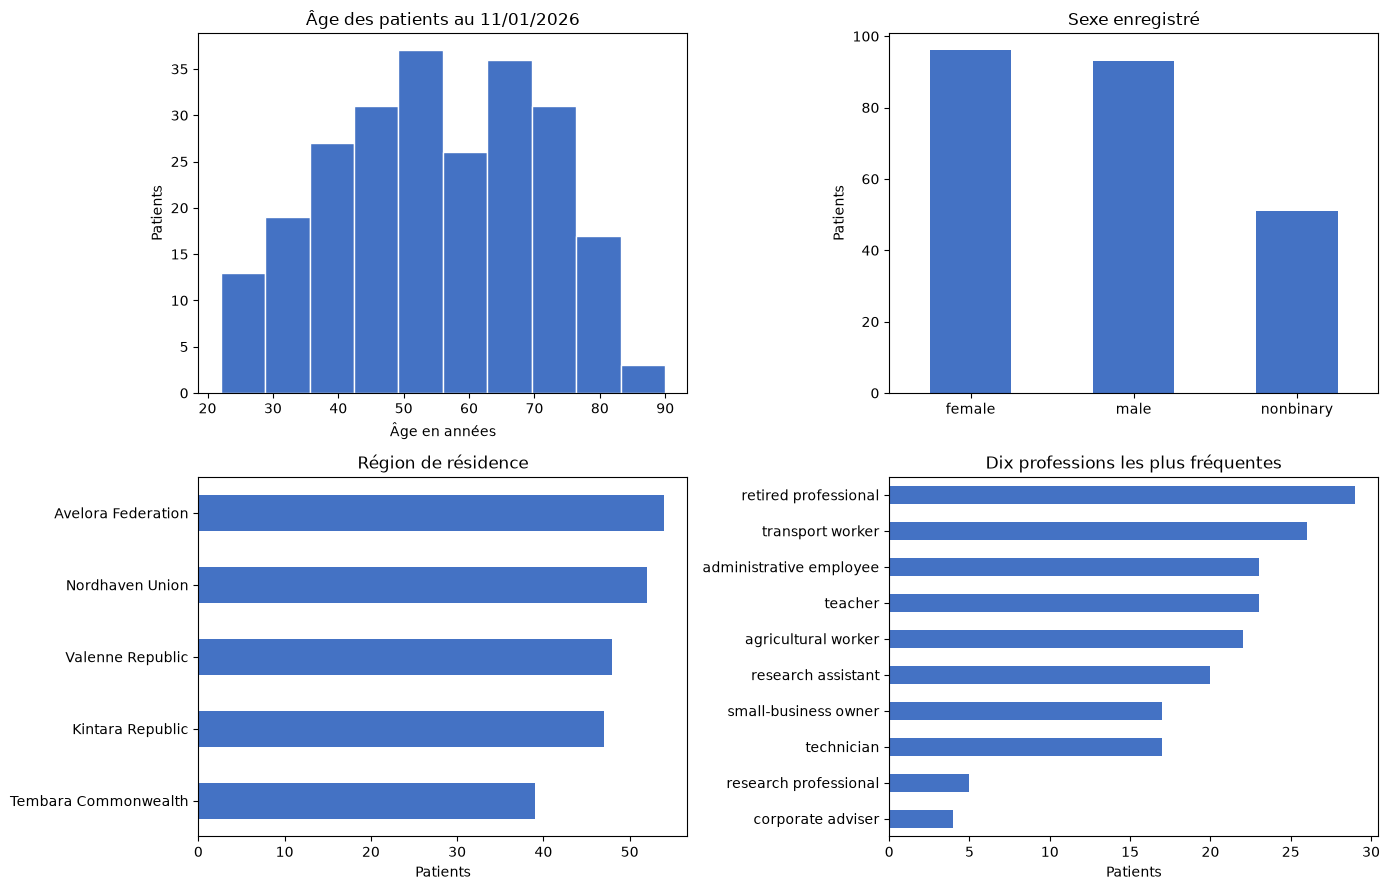

In [19]:
import matplotlib.pyplot as plt

OUT = Path("outputs") / "sante"
OUT.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].hist(patients["age"], bins=10, color="#4472C4", edgecolor="white")
axes[0, 0].set_title("Âge des patients au 11/01/2026")
axes[0, 0].set_xlabel("Âge en années")
axes[0, 0].set_ylabel("Patients")

counts_by_column["registered_sex"]["patients"].plot.bar(
    ax=axes[0, 1], color="#4472C4", rot=0
)
axes[0, 1].set_title("Sexe enregistré")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("Patients")

counts_by_column["home_region"].sort_values("patients")["patients"].plot.barh(
    ax=axes[1, 0], color="#4472C4"
)
axes[1, 0].set_title("Région de résidence")
axes[1, 0].set_xlabel("Patients")
axes[1, 0].set_ylabel("")

counts_by_column["occupation_text"].head(10).sort_values("patients")["patients"].plot.barh(
    ax=axes[1, 1], color="#4472C4"
)
axes[1, 1].set_title("Dix professions les plus fréquentes")
axes[1, 1].set_xlabel("Patients")
axes[1, 1].set_ylabel("")

plt.tight_layout()
plt.savefig(OUT / "profil_patients.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.3 Confidentialité des consultations

La confidentialité concerne les consultations. Un même patient peut apparaître dans plusieurs niveaux.

In [20]:
encounters = clean["encounters"]
confidentiality = encounters.groupby("confidentiality_class").agg(
    consultations=("encounter_number", "size"),
    patients=("patient_number", "nunique")
)
confidentiality["% des consultations"] = (
    100 * confidentiality["consultations"] / len(encounters)
).round(1)
confidentiality.sort_values("consultations", ascending=False)

,consultations,patients,% des consultations
confidentiality_class,,,
standard,581,232,54.5
confidential,295,187,27.6
restricted,191,108,17.9


**Résultats.** L'âge moyen est de 54,9 ans et l'âge médian de 54 ans, avec des âges de 22 à 90 ans à la date de référence.

Les patients viennent de cinq régions. Avelora Federation est la plus représentée avec 54 patients. Les professions les plus fréquentes sont `retired professional` (29) et `transport worker` (26).

Sur les 1 067 consultations, 581 sont `standard`, 295 `confidential` et 191 `restricted`. Les consultations restreintes concernent 108 patients.

## 3. Étudier les mesures médicales

On commence par convertir les valeurs en nombres. Certaines utilisent une virgule décimale ou contiennent leur unité, comme `72.2 bpm`. On retire cette unité seulement si elle correspond à la colonne `unit`.

In [21]:
observations = clean["observations"]
original = observations["numeric_value"].astype("string")
commas = original.str.contains(",", regex=False, na=False)
values = original.str.replace(",", ".", regex=False).str.strip()

# retirer uniquement l'unite indiquee dans la colonne unit
unit_corrections = 0
for unit in observations["unit"].dropna().unique():
    with_unit = observations["unit"].eq(unit) & values.str.endswith(" " + unit, na=False)
    unit_corrections += int(with_unit.sum())
    values.loc[with_unit] = values.loc[with_unit].str.removesuffix(" " + unit).str.strip()

observations["numeric_value"] = pd.to_numeric(values, errors="coerce")
failed = original.notna() & observations["numeric_value"].isna()
if failed.any():
    display(observations.loc[failed, ["observation_number", "observation_code", "unit"]])
    display(original[failed])

pd.DataFrame([{
    "valeurs renseignées": int(original.notna().sum()),
    "virgules décimales": int(commas.sum()),
    "unités dans la valeur": unit_corrections,
    "échecs de conversion": int(failed.sum())
}])

,valeurs renseignées,virgules décimales,unités dans la valeur,échecs de conversion
0,15864,180,160,0


### 3.1 Pouls apical et pouls périphérique

On compare `APICAL` et `PPULSE` pour le même patient et la même consultation. Les valeurs doivent être renseignées et exprimées en bpm (battements par minute).

In [22]:
pulse = observations[observations["observation_code"].isin(["APICAL", "PPULSE"])].copy()

pulse.groupby(["observation_code", "unit"], dropna=False).agg(
    mesures=("observation_number", "size"),
    consultations=("encounter_number", "nunique"),
    patients=("patient_number", "nunique")
)

,,mesures,consultations,patients
observation_code,unit,,,
APICAL,bpm,1017,1017,240
PPULSE,bpm,1017,1017,240


In [23]:
columns = [
    "patient_number", "encounter_number", "numeric_value", "observation_time",
    "unit", "device_reference"
]
apical = pulse.loc[pulse["observation_code"].eq("APICAL"), columns]
peripheral = pulse.loc[pulse["observation_code"].eq("PPULSE"), columns]

# one_to_one empeche de multiplier les lignes si un code est repete dans une consultation
pulse_pairs = apical.merge(
    peripheral, on=["patient_number", "encounter_number"],
    suffixes=("_apical", "_peripheral"), how="outer", indicator=True,
    validate="one_to_one"
)

valid_pair = (
    pulse_pairs["_merge"].eq("both")
    & pulse_pairs["unit_apical"].eq("bpm")
    & pulse_pairs["unit_peripheral"].eq("bpm")
    & pulse_pairs["numeric_value_apical"].notna()
    & pulse_pairs["numeric_value_peripheral"].notna()
    & pulse_pairs["observation_time_apical"].notna()
    & pulse_pairs["observation_time_peripheral"].notna()
)
pulse_comparison = pulse_pairs.loc[valid_pair].copy()
pulse_comparison["delay_seconds"] = (
    pulse_comparison["observation_time_peripheral"]
    - pulse_comparison["observation_time_apical"]
).dt.total_seconds()

pd.DataFrame({
    "contrôle": [
        "Paires retenues", "Paires sans correspondance", "Paires non comparables",
        "Patients comparés", "Délai minimum (secondes)", "Délai maximum (secondes)",
        "Référence appareil différente", "Mesures de qualité autre qu'acceptable"
    ],
    "valeur": [
        len(pulse_comparison), int(pulse_pairs["_merge"].ne("both").sum()),
        int((~valid_pair).sum()), pulse_comparison["patient_number"].nunique(),
        pulse_comparison["delay_seconds"].min(), pulse_comparison["delay_seconds"].max(),
        int(pulse_comparison["device_reference_apical"].ne(pulse_comparison["device_reference_peripheral"]).sum()),
        int(pulse["quality_code"].str.strip().str.lower().ne("acceptable").sum())
    ]
})

,contrôle,valeur
0,Paires retenues,1017.0
1,Paires sans correspondance,0.0
2,Paires non comparables,0.0
3,Patients comparés,240.0
4,Délai minimum (secondes),30.0
5,Délai maximum (secondes),30.0
6,Référence appareil différente,0.0
7,Mesures de qualité autre qu'acceptable,0.0


Les 1 017 paires concernent les 240 patients. Les deux relevés sont espacés de 30 secondes et portent la même référence d'appareil.

On calcule l'écart : **pouls apical − pouls périphérique**. Un écart positif signifie que la valeur apicale est plus élevée.

In [24]:
pulse_comparison["difference"] = (
    pulse_comparison["numeric_value_apical"] - pulse_comparison["numeric_value_peripheral"]
)

pulse_comparison[["numeric_value_apical", "numeric_value_peripheral", "difference"]].rename(
    columns={"numeric_value_apical": "apical (bpm)",
             "numeric_value_peripheral": "périphérique (bpm)",
             "difference": "écart (bpm)"}
).describe().round(2)

,apical (bpm),périphérique (bpm),écart (bpm)
count,1017.0,1017.0,1017.0
mean,77.08,73.12,3.96
std,12.12,9.49,9.04
min,42.0,43.3,-16.7
25%,68.6,66.7,-2.0
50%,76.3,73.2,2.7
75%,85.1,79.4,8.1
max,106.7,99.7,37.4


On calcule les corrélations de Pearson et Spearman. Ici, on prend la médiane des deux pouls par patient pour donner le même poids à chacun.

In [25]:
patient_pulses = pulse_comparison.groupby("patient_number")[[
    "numeric_value_apical", "numeric_value_peripheral"
]].median()

pd.DataFrame([{
    "patients": len(patient_pulses),
    "Pearson": patient_pulses["numeric_value_apical"].corr(
        patient_pulses["numeric_value_peripheral"], method="pearson"
    ),
    "Spearman": patient_pulses["numeric_value_apical"].corr(
        patient_pulses["numeric_value_peripheral"], method="spearman"
    )
}]).round(3)

,patients,Pearson,Spearman
0,240,0.757,0.754


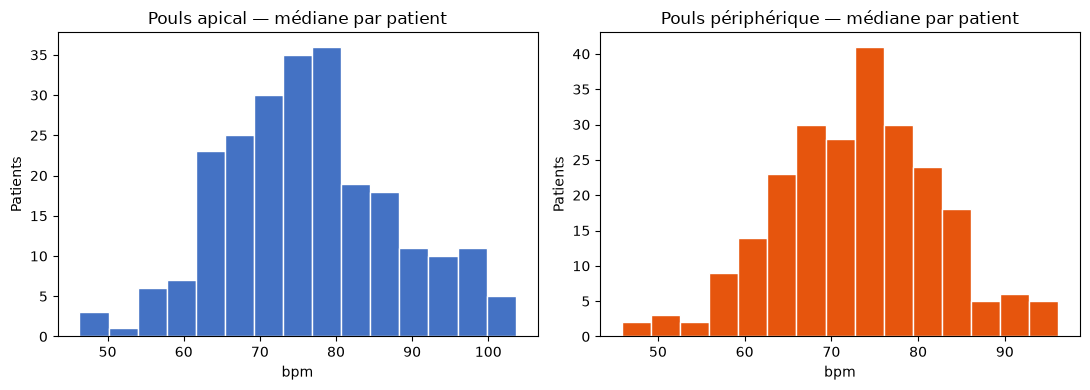

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, title, color in zip(
    axes, ["numeric_value_apical", "numeric_value_peripheral"],
    ["Pouls apical", "Pouls périphérique"], ["#4472C4", "#E6550D"]
):
    ax.hist(patient_pulses[col], bins=15, color=color, edgecolor="white")
    ax.set_title(title + " — médiane par patient")
    ax.set_xlabel("bpm")
    ax.set_ylabel("Patients")

plt.tight_layout()
plt.savefig(OUT / "distribution_pouls_patients.png", dpi=150, bbox_inches="tight")
plt.show()

Les corrélations sur les médianes des 240 patients sont de **0,757 pour Pearson** et **0,754 pour Spearman**. Les deux pouls présentent une association positive.

Pour repérer les écarts éloignés du reste, on utilise les bornes **Q1 − 1,5 × IQR** et **Q3 + 1,5 × IQR**, avec IQR = Q3 − Q1. Ce sont des repères statistiques, pas des seuils médicaux.

In [27]:
q1, q3 = pulse_comparison["difference"].quantile([0.25, 0.75])
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

pulse_comparison["ecart_atypique"] = (
    (pulse_comparison["difference"] < lower) | (pulse_comparison["difference"] > upper)
)
atypical_pulse = pulse_comparison[pulse_comparison["ecart_atypique"]].copy()

print("Bornes exploratoires :", round(lower, 2), "à", round(upper, 2), "bpm")
print("Paires repérées :", len(atypical_pulse))
print("Patients concernés :", atypical_pulse["patient_number"].nunique())

# afficher les cinq plus grands ecarts en valeur absolue
largest = pulse_comparison["difference"].abs().nlargest(5).index
pulse_comparison.loc[largest, [
    "patient_number", "encounter_number", "observation_time_apical",
    "numeric_value_apical", "numeric_value_peripheral", "difference"
]]

Bornes exploratoires : -17.15 à 23.25 bpm
Paires repérées : 50
Patients concernés : 18


,patient_number,encounter_number,observation_time_apical,numeric_value_apical,numeric_value_peripheral,difference
900,PAT-31215,ENC-000023,2018-06-11 09:27:30,102.0,64.6,37.4
879,PAT-31209,ENC-000738,2020-08-25 12:27:30,99.8,63.0,36.8
905,PAT-31215,ENC-000028,2025-09-07 14:27:30,94.2,59.0,35.2
270,PAT-31065,ENC-000035,2020-02-28 10:27:30,99.4,64.3,35.1
365,PAT-31086,ENC-000046,2019-09-15 10:27:30,104.8,71.1,33.7


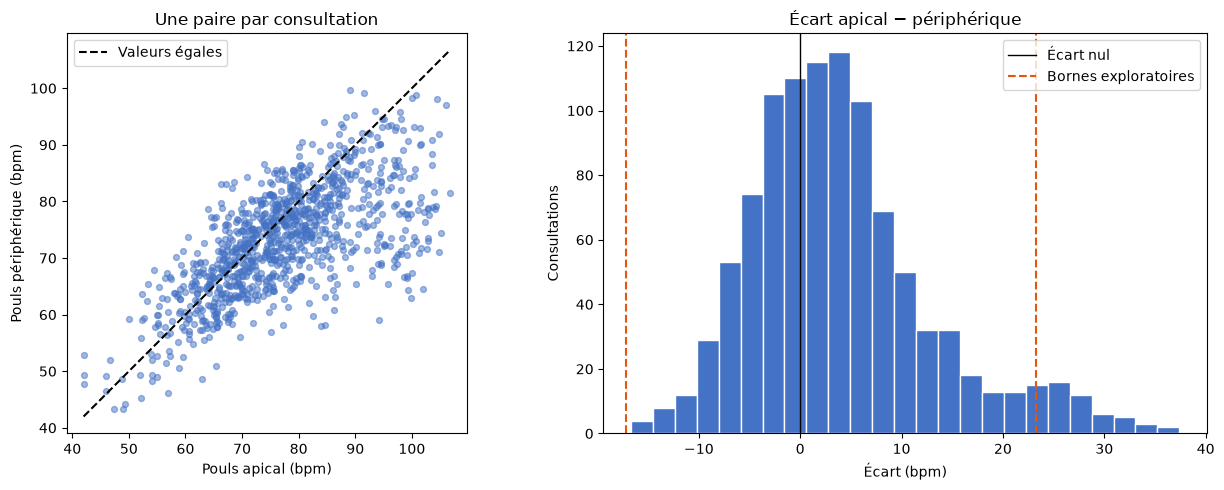

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(
    pulse_comparison["numeric_value_apical"], pulse_comparison["numeric_value_peripheral"],
    s=18, alpha=0.5, color="#4472C4"
)
minimum = pulse_comparison[["numeric_value_apical", "numeric_value_peripheral"]].min().min()
maximum = pulse_comparison[["numeric_value_apical", "numeric_value_peripheral"]].max().max()
axes[0].plot([minimum, maximum], [minimum, maximum], "--", color="black", label="Valeurs égales")
axes[0].set_xlim(minimum - 3, maximum + 3)
axes[0].set_ylim(minimum - 3, maximum + 3)
axes[0].set_aspect("equal", adjustable="box")
axes[0].set_title("Une paire par consultation")
axes[0].set_xlabel("Pouls apical (bpm)")
axes[0].set_ylabel("Pouls périphérique (bpm)")
axes[0].legend()

axes[1].hist(pulse_comparison["difference"], bins=25, color="#4472C4", edgecolor="white")
axes[1].axvline(0, color="black", linewidth=1, label="Écart nul")
axes[1].axvline(lower, color="#E6550D", linestyle="--", label="Bornes exploratoires")
axes[1].axvline(upper, color="#E6550D", linestyle="--")
axes[1].set_title("Écart apical − périphérique")
axes[1].set_xlabel("Écart (bpm)")
axes[1].set_ylabel("Consultations")
axes[1].legend()

plt.tight_layout()
plt.savefig(OUT / "comparaison_pouls.png", dpi=150, bbox_inches="tight")
plt.show()

**Résultats.** Le pouls apical moyen est de 77,08 bpm, contre 73,12 bpm pour le pouls périphérique. L'écart moyen est de **3,96 bpm** et l'écart médian de 2,7 bpm.

La règle des quartiles repère **50 paires chez 18 patients**. Le plus grand écart est de 37,4 bpm pour `PAT-31215`, consultation `ENC-000023`. Ces lignes sont conservées pour examiner leur contexte.

Plusieurs consultations viennent du même patient. Ces statistiques décrivent les consultations observées ; elles ne constituent pas un diagnostic.

### 3.2 Suivre un patient dans le temps

On choisit `PAT-31215`, qui présente le plus grand écart entre les deux pouls. C'est un cas ciblé, qui ne représente pas l'ensemble des patients.

La variable `PATIENT` permet de changer le dossier étudié.

Les visites sont irrégulières. On reste sur un suivi descriptif : six visites ne suffisent pas à étudier une saisonnalité.

In [29]:
PATIENT = "PAT-31215"

patient_encounters = clean["encounters"][
    clean["encounters"]["patient_number"].eq(PATIENT)
].sort_values("encounter_start").copy()
patient_procedures = clean["procedures"][
    clean["procedures"]["patient_number"].eq(PATIENT)
].sort_values("performed_time").copy()
patient_observations = clean["observations"][
    clean["observations"]["patient_number"].eq(PATIENT)
].sort_values("observation_time").copy()

print("Patient :", PATIENT)
print("Consultations :", len(patient_encounters))
print("Procédures :", len(patient_procedures))
print("Observations :", len(patient_observations))

Patient : PAT-31215
Consultations : 6
Procédures : 1
Observations : 95


On rassemble les consultations et les procédures dans une chronologie. Le fichier `licensed_facilities.csv` permet d'ajouter le nom des établissements.

In [30]:
facilities = pd.read_csv(DATA / "public_records/licensed_facilities.csv", dtype=str)
facility_names = facilities.set_index(
    "facility_license_number", verify_integrity=True
)["facility_name"]

rows = []
for _, row in patient_encounters.iterrows():
    rows.append({
        "date": row["encounter_start"],
        "événement": "Consultation",
        "référence": row["encounter_number"],
        "consultation": row["encounter_number"],
        "description": row["encounter_type"],
        "établissement": row["facility_license_number"]
    })
for _, row in patient_procedures.iterrows():
    rows.append({
        "date": row["performed_time"],
        "événement": "Procédure",
        "référence": row["procedure_record_id"],
        "consultation": row["encounter_number"],
        "description": row["procedure_description"],
        "établissement": row["performing_facility_license"]
    })

chronology = pd.DataFrame(rows).sort_values("date").reset_index(drop=True)
# garder le code si le nom d'un etablissement n'est pas disponible
chronology["établissement"] = chronology["établissement"].map(facility_names).fillna(
    chronology["établissement"]
)
chronology

,date,événement,référence,consultation,description,établissement
0,2018-06-11 09:15:00,Consultation,ENC-000023,ENC-000023,cardiac_assessment,Asterion Avelora Executive Clinic
1,2019-11-30 10:15:00,Consultation,ENC-000024,ENC-000024,cardiac_assessment,Asterion Avelora Executive Clinic
2,2021-06-07 11:15:00,Consultation,ENC-000025,ENC-000025,ocular_assessment,Asterion Avelora Executive Clinic
3,2022-11-15 12:15:00,Consultation,ENC-000026,ENC-000026,mobility_assessment,Asterion Avelora Executive Clinic
4,2024-03-27 13:15:00,Consultation,ENC-000027,ENC-000027,cardiac_assessment,Asterion Avelora Executive Clinic
5,2024-03-27 13:45:00,Procédure,PRC-000074,ENC-000027,Biological-age laboratory panel,Asterion Avelora Executive Clinic
6,2025-09-07 14:15:00,Consultation,ENC-000028,ENC-000028,mobility_assessment,Asterion Avelora Executive Clinic


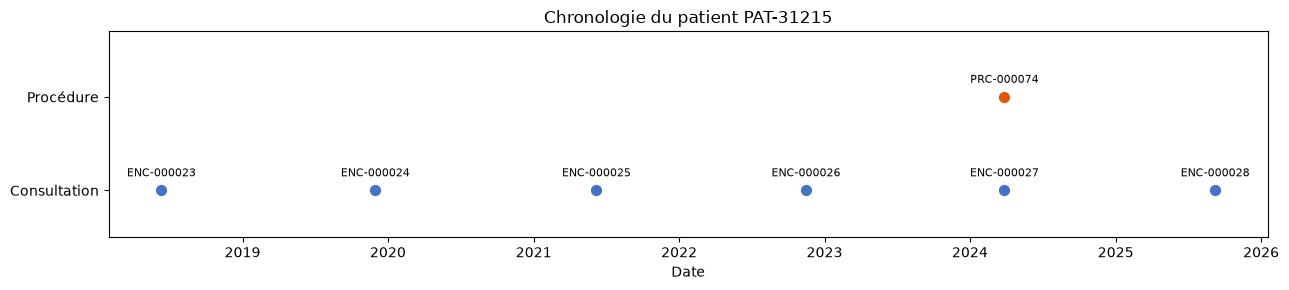

In [31]:
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(13, 3))
for position, (event, color) in enumerate([
    ("Consultation", "#4472C4"), ("Procédure", "#E6550D")
]):
    events = chronology[chronology["événement"].eq(event)]
    ax.scatter(events["date"], [position] * len(events), color=color, s=50)
    for _, row in events.iterrows():
        ax.annotate(
            row["référence"], (row["date"], position),
            xytext=(0, 10), textcoords="offset points", ha="center", fontsize=8
        )

ax.set_yticks([0, 1], ["Consultation", "Procédure"])
ax.set_ylim(-0.5, 1.7)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_xlabel("Date")
ax.set_title("Chronologie du patient " + PATIENT)
plt.tight_layout()
plt.savefig(OUT / f"chronologie_{PATIENT}.png", dpi=150, bbox_inches="tight")
plt.show()

On suit ensuite les mêmes codes avec les mêmes unités à chaque consultation. Les cases sans mesure restent manquantes.

In [32]:
MEASURES = {
    "APICAL": "bpm",
    "PPULSE": "bpm",
    "O2SAT": "%",
    "MOBILITY": "index",
    "COGNITIVE": "index"
}

selected = patient_observations[
    patient_observations["observation_code"].isin(MEASURES)
].copy()
correct_unit = selected["unit"].eq(selected["observation_code"].map(MEASURES))
print("Mesures écartées pour unité inattendue :", int((~correct_unit).sum()))

# pivot signale une erreur si un code apparait plusieurs fois dans une consultation
wide = selected.loc[correct_unit].pivot(
    index="encounter_number", columns="observation_code", values="numeric_value"
).reindex(columns=list(MEASURES))

# garder toutes les consultations, meme si une mesure est absente
longitudinal = patient_encounters[["encounter_number", "encounter_start"]].merge(
    wide, left_on="encounter_number", right_index=True, how="left", validate="one_to_one"
).sort_values("encounter_start").set_index("encounter_start")
longitudinal

Mesures écartées pour unité inattendue : 0


,encounter_number,APICAL,PPULSE,O2SAT,MOBILITY,COGNITIVE
encounter_start,,,,,,
2018-06-11 09:15:00,ENC-000023,102.0,64.6,96.4,87.7,95.3
2019-11-30 10:15:00,ENC-000024,86.3,60.8,96.4,81.7,94.5
2021-06-07 11:15:00,ENC-000025,92.9,66.8,96.6,88.1,<NA>
2022-11-15 12:15:00,ENC-000026,84.6,58.1,96.0,82.6,94.3
2024-03-27 13:15:00,ENC-000027,82.1,66.1,95.9,80.2,91.5
2025-09-07 14:15:00,ENC-000028,94.2,59.0,95.8,81.6,95.9


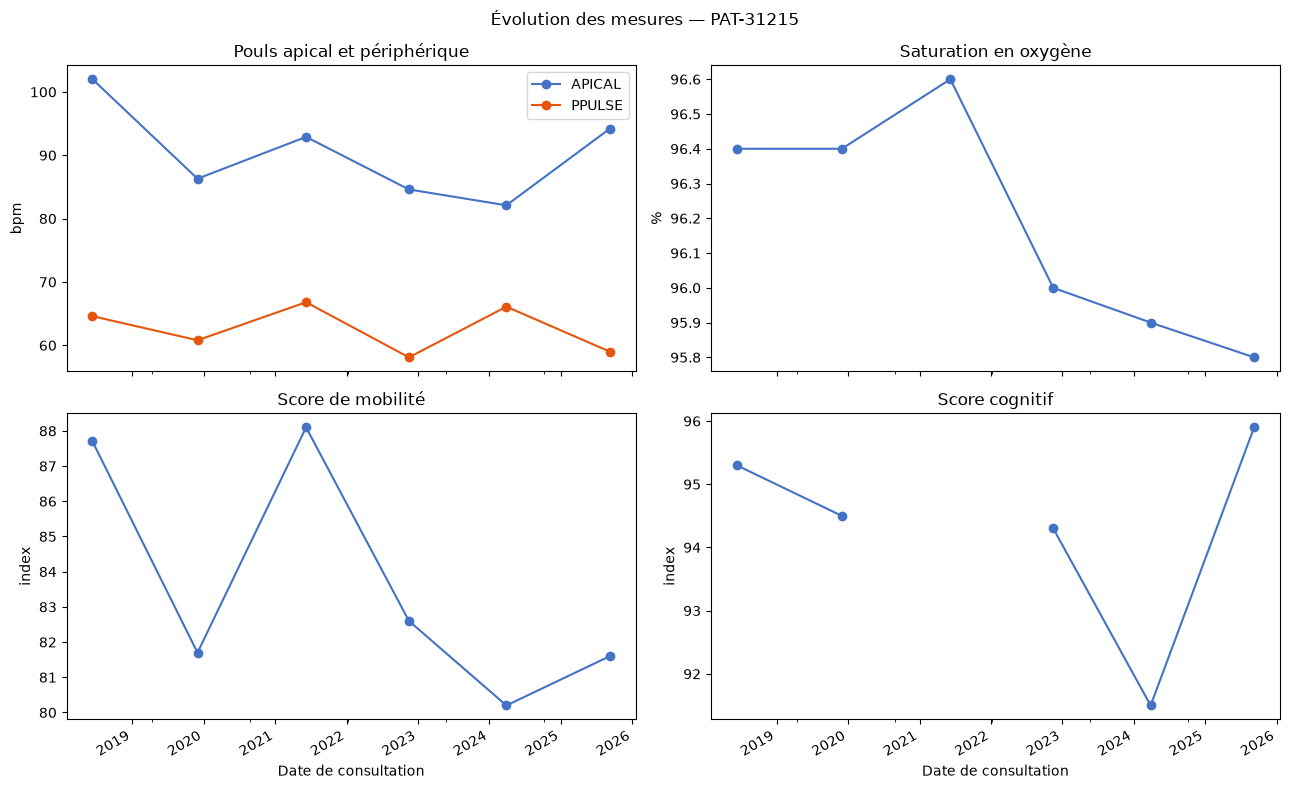

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
plots = [
    (["APICAL", "PPULSE"], "Pouls apical et périphérique", "bpm"),
    (["O2SAT"], "Saturation en oxygène", "%"),
    (["MOBILITY"], "Score de mobilité", "index"),
    (["COGNITIVE"], "Score cognitif", "index")
]

for ax, (codes, title, unit) in zip(axes.flat, plots):
    longitudinal[codes].plot(
        ax=ax, marker="o", color=["#4472C4", "#E6550D"][:len(codes)],
        legend=len(codes) > 1
    )
    ax.set_title(title)
    ax.set_ylabel(unit)
    ax.set_xlabel("Date de consultation")

fig.suptitle("Évolution des mesures — " + PATIENT)
plt.tight_layout()
plt.savefig(OUT / f"mesures_{PATIENT}.png", dpi=150, bbox_inches="tight")
plt.show()

**Lecture du parcours.** Ce patient a six consultations entre 2018 et 2025, toutes à l'Asterion Avelora Executive Clinic. Une procédure `AGE-PNL` est enregistrée le 27 mars 2024.

Le pouls apical reste supérieur au pouls périphérique lors des six consultations, avec des écarts de 16 à 37,4 bpm. La saturation varie de 95,8 à 96,6 %.

Le score cognitif manque à la consultation de 2021 : la case reste vide et la courbe est interrompue à cet endroit. Ce parcours sert à décrire les mesures observées, sans conclure à une maladie.

### 3.3 Une incohérence entre valeur et interprétation

On compare les deux pouls à l'intervalle indiqué dans `reference_range_text`. On signale les valeurs hors de cet intervalle qui portent pourtant le code `within_expected_range`.

Cette vérification concerne uniquement `APICAL` et `PPULSE` en bpm.

In [34]:
range_check = clean["observations"][
    clean["observations"]["observation_code"].isin(["APICAL", "PPULSE"])
    & clean["observations"]["unit"].eq("bpm")
].copy()

# lire les bornes des intervalles fournis, comme 50–110
bounds = range_check["reference_range_text"].str.extract(r"^\s*(\d+)\s*[–-]\s*(\d+)\s*$")
range_check["reference_min"] = pd.to_numeric(bounds[0], errors="coerce")
range_check["reference_max"] = pd.to_numeric(bounds[1], errors="coerce")

comparable = (
    range_check["numeric_value"].notna()
    & range_check["reference_min"].notna()
    & range_check["reference_max"].notna()
    & range_check["reference_min"].le(range_check["reference_max"])
)
outside_reference = comparable & (
    range_check["numeric_value"].lt(range_check["reference_min"])
    | range_check["numeric_value"].gt(range_check["reference_max"])
)
interpretation = range_check["interpretation_code"].str.strip().str.lower()
range_check["incoherence_interpretation"] = (
    outside_reference & interpretation.eq("within_expected_range")
)
range_inconsistencies = range_check[range_check["incoherence_interpretation"]].copy()

pd.DataFrame([{
    "mesures comparées": int(comparable.sum()),
    "mesures non vérifiables": int((~comparable).sum()),
    "décalages valeur / interprétation": len(range_inconsistencies),
    "patients concernés": range_inconsistencies["patient_number"].nunique(),
    "consultations concernées": range_inconsistencies["encounter_number"].nunique()
}])

,mesures comparées,mesures non vérifiables,décalages valeur / interprétation,patients concernés,consultations concernées
0,2034,0,25,6,17


On retrouve 25 décalages de ce type chez 6 patients. On documente l'observation `OBS-0001802`, associée au patient `PAT-31231` et à la consultation `ENC-000138`.

In [35]:
CASE = "OBS-0001802"
case = range_inconsistencies[
    range_inconsistencies["observation_number"].eq(CASE)
].merge(
    clean["encounters"][[
        "encounter_number", "patient_number", "encounter_start", "encounter_end",
        "encounter_type", "service_unit", "confidentiality_class"
    ]],
    on="encounter_number", suffixes=("", "_consultation"),
    how="left", validate="many_to_one"
)

case[[
    "observation_number", "patient_number", "encounter_number", "observation_code",
    "numeric_value", "unit", "reference_range_text", "interpretation_code"
]]

,observation_number,patient_number,encounter_number,observation_code,numeric_value,unit,reference_range_text,interpretation_code
0,OBS-0001802,PAT-31231,ENC-000138,APICAL,42.0,bpm,50–110,within_expected_range


In [36]:
source_case = raw["observations"][raw["observations"]["observation_number"].eq(CASE)]
inside_encounter = (
    case["observation_time"].ge(case["encounter_start"])
    & case["observation_time"].le(case["encounter_end"])
)

pd.DataFrame({
    "contrôle": [
        "Une seule ligne source pour cet identifiant",
        "Unité égale à bpm",
        "Même patient que la consultation",
        "Mesure prise pendant la consultation",
        "Code qualité égal à acceptable",
        "Référence d'appareil renseignée"
    ],
    "vérifié": [
        len(source_case) == 1,
        bool(case["unit"].eq("bpm").all()),
        bool(case["patient_number"].eq(case["patient_number_consultation"]).all()),
        bool(inside_encounter.all()),
        bool(case["quality_code"].str.strip().str.lower().eq("acceptable").all()),
        bool(case["device_reference"].notna().all())
    ]
})

,contrôle,vérifié
0,Une seule ligne source pour cet identifiant,True
1,Unité égale à bpm,True
2,Même patient que la consultation,True
3,Mesure prise pendant la consultation,True
4,Code qualité égal à acceptable,True
5,Référence d'appareil renseignée,True


Pour le contexte, on affiche les trois relevés de pouls de la même consultation.

In [37]:
case_encounter = case["encounter_number"].iloc[0]
context = clean["observations"][
    clean["observations"]["encounter_number"].eq(case_encounter)
    & clean["observations"]["observation_code"].isin(["RPULSE", "APICAL", "PPULSE"])
].sort_values("observation_time")

context[[
    "observation_number", "observation_time", "observation_code", "numeric_value",
    "unit", "reference_range_text", "interpretation_code", "device_reference"
]]

,observation_number,observation_time,observation_code,numeric_value,unit,reference_range_text,interpretation_code,device_reference
1800,OBS-0001801,2019-09-18 11:27:00,RPULSE,80.1,bpm,50–100,within_expected_range,DEV-007
1801,OBS-0001802,2019-09-18 11:27:30,APICAL,42.0,bpm,50–110,within_expected_range,DEV-007
1802,OBS-0001803,2019-09-18 11:28:00,PPULSE,52.9,bpm,50–100,within_expected_range,DEV-007


**Cas documenté.** Le 18 septembre 2019, l'observation `OBS-0001802` indique un pouls apical de **42 bpm**, sous la borne de 50 bpm fournie dans le fichier. Le code reste `within_expected_range`.

La ligne source est unique, l'unité est cohérente et la mesure est prise pendant la consultation. La référence d'appareil est `DEV-007` et le code qualité indique `acceptable`.

**Décision :** conserver la valeur et signaler le décalage dans `range_inconsistencies`. Il faut vérifier comment l'interprétation a été produite et si l'intervalle convient au contexte. Les données seules ne permettent pas de choisir quel champ corriger ni de poser un diagnostic.

## 4. Regrouper les patients par profil

On utilise les k-means. Chaque patient est représenté par trois variables :

- son âge au 11 janvier 2026 ;
- la médiane des écarts apical − périphérique, en bpm ;
- la médiane du débit cardiaque estimé (`CARDOUT`), en L/min.

Ces variables décrivent l'âge et deux aspects des mesures cardiaques. Les médianes résument des consultations à des dates différentes. On regroupe ces résumés, pas des courbes alignées.

In [38]:
# une ligne par patient ; calculer d'abord les ecarts par consultation
median_gap = pulse_comparison.groupby("patient_number")["difference"].median()
median_gap = median_gap.rename("ecart_pouls_median")

cardout = clean["observations"][
    clean["observations"]["observation_code"].eq("CARDOUT")
    & clean["observations"]["unit"].eq("L/min")
]
median_cardout = cardout.groupby("patient_number")["numeric_value"].median()
median_cardout = median_cardout.rename("debit_median")

FEATURES = ["age", "ecart_pouls_median", "debit_median"]
profiles = clean["patients"].set_index("patient_number")[["age"]].join(
    median_gap, validate="one_to_one"
).join(median_cardout, validate="one_to_one")

display(profiles.isna().sum().rename("valeurs manquantes").to_frame())
fit_profiles = profiles.dropna(subset=FEATURES).copy()
print("Patients conservés :", len(fit_profiles))
print("Patients écartés pour données manquantes :", len(profiles) - len(fit_profiles))

,valeurs manquantes
age,0
ecart_pouls_median,0
debit_median,0


Patients conservés : 240
Patients écartés pour données manquantes : 0


### 4.1 Variables et échelles

On vérifie les corrélations pour éviter de donner plusieurs fois du poids à la même information.

La distance euclidienne convient ici à trois variables numériques. Comme leurs unités diffèrent, on les centre et on les réduit pour comparer les écarts à leur propre dispersion. Les résultats restent interprétés dans les unités d'origine.

In [39]:
for method in ["pearson", "spearman"]:
    print(method.capitalize())
    display(fit_profiles[FEATURES].corr(method=method).round(2))

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(fit_profiles[FEATURES])

Pearson


,age,ecart_pouls_median,debit_median
age,1.00,-0.08,0.00
ecart_pouls_median,-0.08,1.00,0.27
debit_median,0.00,0.27,1.00


Spearman


,age,ecart_pouls_median,debit_median
age,1.00,-0.05,0.01
ecart_pouls_median,-0.05,1.00,0.07
debit_median,0.01,0.07,1.00


### 4.2 Choix du nombre de groupes

On compare de 2 à 6 groupes, avec 20 initialisations par essai et une graine fixée pour reproduire le résultat.

On retient le meilleur score de silhouette parmi ces essais : un score élevé indique des groupes plus compacts et mieux séparés. L'inertie mesure la dispersion autour des centres. Ce choix reste exploratoire.

In [40]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

models = {}
rows = []
for k in range(2, 7):
    model = KMeans(n_clusters=k, init="k-means++", n_init=20, random_state=42)
    labels = model.fit_predict(X)
    models[k] = model
    rows.append({
        "k": k,
        "inertie": model.inertia_,
        "silhouette": silhouette_score(X, labels),
        "plus petit groupe": int(pd.Series(labels).value_counts().min())
    })

clustering_scores = pd.DataFrame(rows).set_index("k")
chosen_k = int(clustering_scores["silhouette"].idxmax())
print("Nombre de groupes retenu :", chosen_k)
clustering_scores.round(3)

Nombre de groupes retenu : 3


,inertie,silhouette,plus petit groupe
k,,,
2,532.278,0.269,111
3,373.701,0.308,23
4,301.082,0.291,22
5,263.189,0.251,20
6,230.759,0.265,11


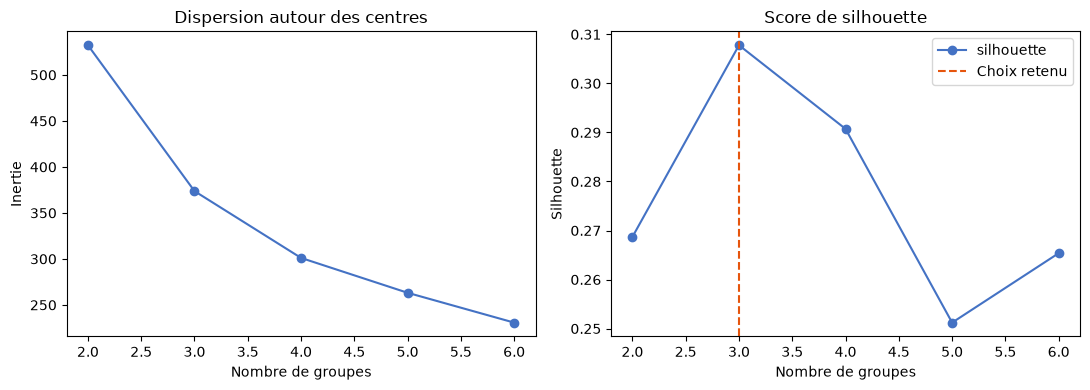

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
clustering_scores["inertie"].plot(ax=axes[0], marker="o", color="#4472C4")
axes[0].set_title("Dispersion autour des centres")
axes[0].set_xlabel("Nombre de groupes")
axes[0].set_ylabel("Inertie")

clustering_scores["silhouette"].plot(ax=axes[1], marker="o", color="#4472C4")
axes[1].axvline(chosen_k, color="#E6550D", linestyle="--", label="Choix retenu")
axes[1].set_title("Score de silhouette")
axes[1].set_xlabel("Nombre de groupes")
axes[1].set_ylabel("Silhouette")
axes[1].legend()
plt.tight_layout()
plt.savefig(OUT / "choix_groupes.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.3 Comparer les groupes

On numérote les groupes par écart de pouls moyen croissant pour faciliter leur lecture. Le tableau présente les médianes dans les unités d'origine.

In [42]:
model = models[chosen_k]
centers = pd.DataFrame(scaler.inverse_transform(model.cluster_centers_), columns=FEATURES)
order = centers.sort_values("ecart_pouls_median").index
label_map = {old_label: number + 1 for number, old_label in enumerate(order)}
fit_profiles["groupe"] = pd.Series(model.labels_, index=fit_profiles.index).map(label_map)

group_summary = fit_profiles.groupby("groupe").agg(
    patients=("age", "size"),
    age_median=("age", "median"),
    ecart_pouls_median_bpm=("ecart_pouls_median", "median"),
    debit_median_L_min=("debit_median", "median")
)
group_summary.round(2)

,patients,age_median,ecart_pouls_median_bpm,debit_median_L_min
groupe,,,,
1,112,43.0,1.98,5.22
2,105,69.0,1.8,5.35
3,23,51.0,19.9,6.63


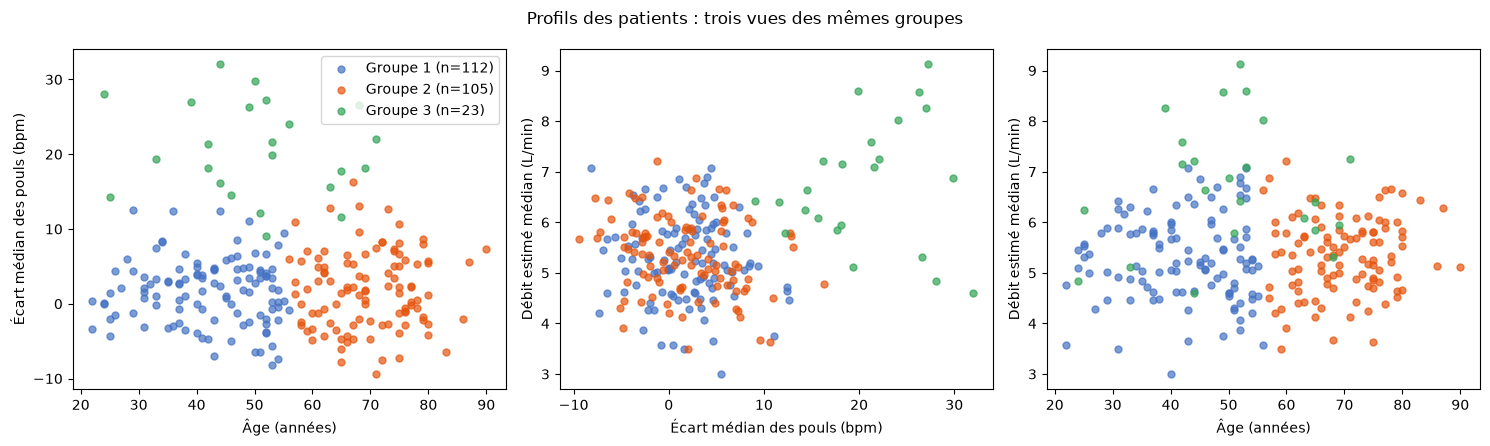

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
comparisons = [
    ("age", "ecart_pouls_median", "Âge (années)", "Écart médian des pouls (bpm)"),
    ("ecart_pouls_median", "debit_median", "Écart médian des pouls (bpm)", "Débit estimé médian (L/min)"),
    ("age", "debit_median", "Âge (années)", "Débit estimé médian (L/min)")
]
colors = ["#4472C4", "#E6550D", "#31A354", "#756BB1", "#A65628", "#E377C2"]
for ax, (x, y, xlabel, ylabel) in zip(axes, comparisons):
    for group, data in fit_profiles.groupby("groupe"):
        ax.scatter(data[x], data[y], color=colors[group - 1], alpha=0.7, s=25,
                   label=f"Groupe {group} (n={len(data)})")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
axes[0].legend()
fig.suptitle("Profils des patients : trois vues des mêmes groupes")
plt.tight_layout()
plt.savefig(OUT / "groupes_patients.png", dpi=150, bbox_inches="tight")
plt.show()

In [44]:
# sexe et region servent a decrire les groupes, sans entrer dans la distance
profile_details = fit_profiles.join(
    clean["patients"].set_index("patient_number")[["registered_sex", "home_region", "occupation_text"]],
    validate="one_to_one"
)
print("Sexe enregistré : effectifs")
display(pd.crosstab(profile_details["groupe"], profile_details["registered_sex"]))
print("Région : effectifs")
display(pd.crosstab(profile_details["groupe"], profile_details["home_region"]))

Sexe enregistré : effectifs


registered_sex,female,male,nonbinary
groupe,,,
1,41,43,28
2,45,41,19
3,10,9,4


Région : effectifs


home_region,Avelora Federation,Kintara Republic,Nordhaven Union,Tembara Commonwealth,Valenne Republic
groupe,,,,,
1,21,25,26,19,21
2,27,20,23,16,19
3,6,2,3,4,8


**Lecture des groupes.**

- **Groupe 1 : 112 patients**, âge médian de 43 ans, écart de pouls médian de 1,98 bpm et débit estimé médian de 5,22 L/min.
- **Groupe 2 : 105 patients**, âge médian de 69 ans, écart de pouls médian de 1,80 bpm et débit estimé médian de 5,35 L/min.
- **Groupe 3 : 23 patients**, âge médian de 51 ans, écart de pouls médian de 19,90 bpm et débit estimé médian de 6,63 L/min.

Les deux premiers groupes se distinguent surtout par l'âge. Le troisième présente des écarts de pouls et un débit estimé plus élevés.

Le score de silhouette de **0,308** indique une séparation modérée. Ces trois groupes restent une proposition exploratoire.

### 4.4 Vérifier l'effet de l'initialisation

Les k-means peuvent changer selon les centres de départ. On recommence avec plusieurs graines et on compare les partitions avec l'indice de Rand ajusté : 1 signifie que les regroupements sont identiques, même si les numéros des groupes changent.

In [45]:
rows = []
for seed in [0, 1, 21, 99]:
    other = KMeans(n_clusters=chosen_k, init="k-means++", n_init=20, random_state=seed)
    other_labels = other.fit_predict(X)
    rows.append({
        "graine": seed,
        "Rand ajusté": adjusted_rand_score(model.labels_, other_labels)
    })
stability = pd.DataFrame(rows)
display(stability.round(3))

# export reproductible des profils et des resultats
profiles.join(fit_profiles[["groupe"]]).to_csv(OUT / "profils_patients.csv")
group_summary.to_csv(OUT / "comparaison_groupes.csv")
clustering_scores.to_csv(OUT / "choix_groupes.csv")

,graine,Rand ajusté
0,0,1.0
1,1,1.0
2,21,1.0
3,99,1.0


**Limites.** Ces groupes dépendent des trois variables choisies et des consultations disponibles. Les médianes masquent une partie de l'évolution dans le temps. Les mesures signalées au §3.3 ont été conservées et restent à vérifier. D'autres variables ou une autre mise à l'échelle pourraient modifier le regroupement.

Les groupes décrivent des profils numériques. Ils ne permettent pas de classer les patients comme malades ou en bonne santé.

## 5. Analyser les procédures

On étudie les 310 actes après retrait des doublons. Ils concernent 180 des 240 patients et sont tous marqués `completed`.

### 5.1 Fréquences

On distingue le nombre d'actes et le nombre de patients concernés : un même patient peut recevoir plusieurs fois la même procédure.

In [46]:
procedures = clean["procedures"]

# inclure les 240 patients ; zero signifie aucun acte enregistre
procedure_counts = pd.crosstab(
    procedures["patient_number"], procedures["procedure_code"]
).reindex(clean["patients"]["patient_number"], fill_value=0)
procedure_presence = procedure_counts.gt(0)

procedure_frequency = procedures.groupby("procedure_code").agg(
    description=("procedure_description", "first"),
    actes=("procedure_record_id", "size"),
    patients=("patient_number", "nunique")
)
procedure_frequency["% des actes"] = 100 * procedure_frequency["actes"] / len(procedures)
procedure_frequency["patients avec répétition"] = procedure_counts.gt(1).sum()
procedure_frequency = procedure_frequency.sort_values("actes", ascending=False)
procedure_frequency.round(1)

,description,actes,patients,% des actes,patients avec répétition
procedure_code,,,,,
OCT-TRK,Ocular tracking assessment,51,48,16.5,3
MRP-42,Targeted metabolic resilience administration,50,28,16.1,8
OCC-PNL,Occupational health assessment,49,47,15.8,2
AUT-REV,Autonomic function review,43,41,13.9,2
CARD-IMG,Advanced cardiac imaging,41,36,13.2,5
AGE-PNL,Biological-age laboratory panel,39,36,12.6,2
MOB-PNL,Mobility and balance panel,37,34,11.9,3


### 5.2 Procédures retrouvées chez les mêmes patients

Il n'y a qu'un acte par consultation. Ici, une association signifie que plusieurs codes sont présents chez le même patient sur l'ensemble de son parcours.

Chaque code compte une seule fois par patient. Le support est calculé sur les 240 patients, y compris les 60 sans acte. On garde les combinaisons présentes chez au moins 5 patients, puis on examine les paires et les triplets.

In [47]:
from itertools import combinations

MIN_PATIENTS = 5
rows = []
for size in [2, 3]:
    for items in combinations(procedure_presence.columns, size):
        count = int(procedure_presence[list(items)].all(axis=1).sum())
        if count >= MIN_PATIENTS:
            rows.append({
                "codes": " + ".join(items),
                "taille": size,
                "patients": count,
                "support %": 100 * count / len(procedure_presence)
            })

frequent_patterns = pd.DataFrame(rows).sort_values(
    ["patients", "codes"], ascending=[False, True]
).reset_index(drop=True)
print("Triplets présents chez au moins 5 patients :", int(frequent_patterns["taille"].eq(3).sum()))
frequent_patterns.round(2)

Triplets présents chez au moins 5 patients : 0


,codes,taille,patients,support %
0,MRP-42 + OCC-PNL,2,10,4.17
1,AUT-REV + OCT-TRK,2,9,3.75
2,OCC-PNL + OCT-TRK,2,9,3.75
3,CARD-IMG + OCC-PNL,2,8,3.33
4,MOB-PNL + MRP-42,2,7,2.92
5,MOB-PNL + OCC-PNL,2,7,2.92
6,MOB-PNL + OCT-TRK,2,7,2.92
7,AGE-PNL + CARD-IMG,2,6,2.50
8,AGE-PNL + OCT-TRK,2,6,2.50
9,AUT-REV + MOB-PNL,2,5,2.08


La confiance A → B est la proportion de patients ayant B parmi ceux ayant A. Le lift compare cette proportion à la fréquence de B dans la population étudiée. Un lift supérieur à 1 signale une présence conjointe plus fréquente que sous indépendance.

In [48]:
rows = []
for code_a, code_b in combinations(procedure_presence.columns, 2):
    count_a = int(procedure_presence[code_a].sum())
    count_b = int(procedure_presence[code_b].sum())
    together = int((procedure_presence[code_a] & procedure_presence[code_b]).sum())
    if together >= MIN_PATIENTS:
        rows.append({
            "A": code_a,
            "B": code_b,
            "patients": together,
            "confiance A → B %": 100 * together / count_a,
            "confiance B → A %": 100 * together / count_b,
            "lift": together * len(procedure_presence) / (count_a * count_b)
        })

association_rules = pd.DataFrame(rows).sort_values("lift", ascending=False).reset_index(drop=True)
association_rules.round(2)

,A,B,patients,confiance A → B %,confiance B → A %,lift
0,MRP-42,OCC-PNL,10,35.71,21.28,1.82
1,MOB-PNL,MRP-42,7,20.59,25.00,1.76
2,CARD-IMG,OCC-PNL,8,22.22,17.02,1.13
3,AGE-PNL,CARD-IMG,6,16.67,16.67,1.11
4,AUT-REV,OCT-TRK,9,21.95,18.75,1.10
5,MOB-PNL,OCC-PNL,7,20.59,14.89,1.05
6,MOB-PNL,OCT-TRK,7,20.59,14.58,1.03
7,OCC-PNL,OCT-TRK,9,19.15,18.75,0.96
8,AUT-REV,MOB-PNL,5,12.20,14.71,0.86
9,AGE-PNL,OCT-TRK,6,16.67,12.50,0.83


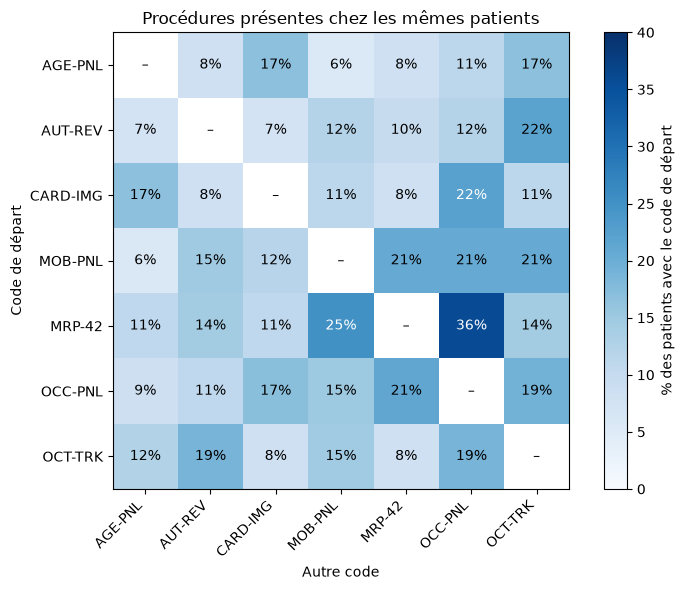

In [49]:
# chaque cellule donne le pourcentage de patients avec le code en colonne
# parmi ceux ayant le code en ligne
presence_numbers = procedure_presence.astype(int)
cooccurrence = presence_numbers.T.dot(presence_numbers)
conditional_presence = cooccurrence.div(procedure_presence.sum(), axis=0) * 100
for code in conditional_presence.index:
    conditional_presence.loc[code, code] = float("nan")

fig, ax = plt.subplots(figsize=(8, 6))
plot = ax.imshow(conditional_presence.to_numpy(), cmap="Blues", vmin=0, vmax=40)
ax.set_xticks(range(len(conditional_presence.columns)), conditional_presence.columns, rotation=45, ha="right")
ax.set_yticks(range(len(conditional_presence.index)), conditional_presence.index)
for row in range(len(conditional_presence.index)):
    for col in range(len(conditional_presence.columns)):
        value = conditional_presence.iloc[row, col]
        label = "–" if pd.isna(value) else f"{value:.0f}%"
        ax.text(col, row, label, ha="center", va="center",
                color="white" if pd.notna(value) and value > 22 else "black")
ax.set_xlabel("Autre code")
ax.set_ylabel("Code de départ")
ax.set_title("Procédures présentes chez les mêmes patients")
fig.colorbar(plot, ax=ax, label="% des patients avec le code de départ")
plt.tight_layout()
plt.savefig(OUT / "associations_procedures.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.3 Patients avec un volume d'actes élevé

On compte les actes par patient, y compris les patients sans acte. La borne Q3 + 1,5 × IQR sert à repérer les volumes élevés à examiner.

In [50]:
procedure_volumes = procedure_counts.sum(axis=1).rename("actes").to_frame()
procedure_volumes["codes différents"] = procedure_presence.sum(axis=1)

procedure_q1, procedure_q3 = procedure_volumes["actes"].quantile([0.25, 0.75])
procedure_iqr = procedure_q3 - procedure_q1
procedure_upper = procedure_q3 + 1.5 * procedure_iqr
unusual_procedure_volumes = procedure_volumes[
    procedure_volumes["actes"] > procedure_upper
].sort_values("actes", ascending=False)

print("Patients sans acte :", int(procedure_volumes["actes"].eq(0).sum()))
print("Borne supérieure :", round(procedure_upper, 3), "actes")
print("Patients au-dessus de la borne :", len(unusual_procedure_volumes))
unusual_procedure_volumes

Patients sans acte : 60
Borne supérieure : 3.875 actes
Patients au-dessus de la borne : 9


,actes,codes différents
patient_number,,
PAT-31044,6,3
PAT-31221,5,1
PAT-31174,5,2
PAT-31119,4,1
PAT-31074,4,1
PAT-31183,4,2
PAT-31002,4,3
PAT-31101,4,3
PAT-31043,4,4


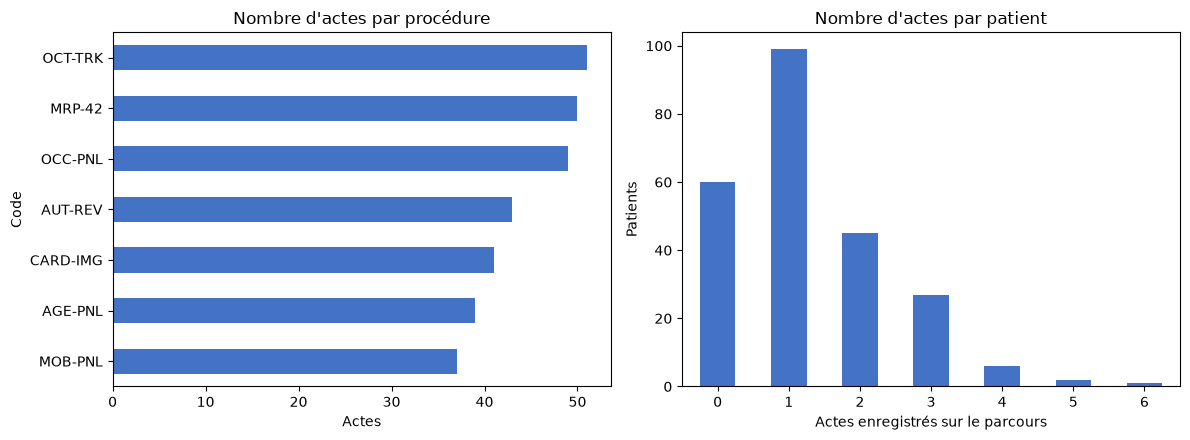

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
procedure_frequency["actes"].sort_values().plot.barh(ax=axes[0], color="#4472C4")
axes[0].set_title("Nombre d'actes par procédure")
axes[0].set_xlabel("Actes")
axes[0].set_ylabel("Code")

volume_distribution = procedure_volumes["actes"].value_counts().sort_index()
volume_distribution.plot.bar(ax=axes[1], color="#4472C4", rot=0)
axes[1].set_title("Nombre d'actes par patient")
axes[1].set_xlabel("Actes enregistrés sur le parcours")
axes[1].set_ylabel("Patients")
plt.tight_layout()
plt.savefig(OUT / "frequences_procedures.png", dpi=150, bbox_inches="tight")
plt.show()

On regarde le patient ayant le plus d'actes pour comprendre ce que ce volume recouvre.

In [52]:
HEAVY_PATIENT = procedure_volumes["actes"].idxmax()
print("Patient :", HEAVY_PATIENT)

procedure_case = procedures[procedures["patient_number"].eq(HEAVY_PATIENT)].sort_values("performed_time")
display(procedure_case[[
    "procedure_record_id", "encounter_number", "performed_time", "procedure_code",
    "procedure_description", "authorization_class"
]])

procedure_frequency.to_csv(OUT / "frequences_procedures.csv")
frequent_patterns.to_csv(OUT / "motifs_procedures.csv", index=False)
association_rules.to_csv(OUT / "associations_procedures.csv", index=False)
unusual_procedure_volumes.to_csv(OUT / "volumes_actes_a_examiner.csv")

Patient : PAT-31044


,procedure_record_id,encounter_number,performed_time,procedure_code,procedure_description,authorization_class
5,PRC-000006,ENC-001023,2017-05-12 09:05:00,MRP-42,Targeted metabolic resilience administration,restricted_specialist
152,PRC-000153,ENC-000063,2017-06-19 10:45:00,MOB-PNL,Mobility and balance panel,standard
6,PRC-000007,ENC-001024,2019-05-17 09:05:00,MRP-42,Targeted metabolic resilience administration,restricted_specialist
156,PRC-000157,ENC-000064,2019-06-29 11:45:00,AUT-REV,Autonomic function review,confidential
7,PRC-000008,ENC-001025,2021-06-04 09:05:00,MRP-42,Targeted metabolic resilience administration,restricted_specialist
8,PRC-000009,ENC-001026,2024-08-23 09:05:00,MRP-42,Targeted metabolic resilience administration,restricted_specialist


**Résultats.** `OCT-TRK` est l'acte le plus fréquent, avec 51 enregistrements chez 48 patients. `MRP-42` compte 50 actes chez 28 patients, dont 8 l'ont reçu plusieurs fois.

La paire `MRP-42` + `OCC-PNL` est retrouvée chez 10 patients, soit 4,17 % des 240 patients. Son lift est de 1,82. Aucun triplet n'atteint 5 patients.

Neuf patients ont un volume élevé selon la règle choisie, avec 4 à 6 actes. `PAT-31044` a 6 actes entre 2017 et 2024, dont 4 `MRP-42`.

Les effectifs des associations restent faibles. Les durées de suivi diffèrent et les patients les plus suivis ont davantage d'occasions de recevoir plusieurs actes. Ces résultats orientent l'exploration sans prouver qu'une procédure est injustifiée.

## 6. Tester des correspondances avec les registres publics

Les données et les personnes sont fictives. On compare l'année de naissance, la région, la profession et les dates des consultations avec les nominations publiques.

Les noms des patients ne servent pas au calcul. Les correspondances restent des hypothèses.

In [53]:
appointments_raw = pd.read_csv(
    DATA / "public_records/public_appointments.csv", dtype=str,
    keep_default_na=False, na_values=[""]
)
appointments = appointments_raw.drop_duplicates().copy()


def normalize_label(series):
    return series.astype("string").str.replace(r"\s+", " ", regex=True).str.strip().str.lower()


REGION_MAP = {
    "aveloran": "avelora federation",
    "kintaran": "kintara republic",
    "tembaran": "tembara commonwealth",
    "valennan": "valenne republic"
}

patient_links = clean["patients"][[
    "patient_number", "date_of_birth", "home_region", "occupation_text"
]].copy()
patient_links["annee_patient"] = patient_links["date_of_birth"].dt.year
patient_links["region_key"] = normalize_label(patient_links["home_region"])
patient_links["job_key"] = normalize_label(patient_links["occupation_text"])

appointments["region_key"] = normalize_label(appointments["official_region"]).map(REGION_MAP)
appointments["job_key"] = normalize_label(appointments["office_title"])
name_key = normalize_label(appointments["office_holder_name"]).str.replace(r"^dr\.\s*", "", regex=True)
appointments["person_key"] = name_key + " | " + appointments["region_key"]
appointments["annee_publique"] = pd.to_numeric(appointments["recorded_birth_year"], errors="coerce")

# completer une annee seulement si les autres notices de meme nom et region concordent
known_year = appointments.groupby("person_key")["annee_publique"].transform(
    lambda values: values.dropna().iloc[0] if values.nunique() == 1 else float("nan")
)
appointments["annee_publique_retenue"] = appointments["annee_publique"].fillna(known_year)
appointments["annee_completee"] = appointments["annee_publique"].isna() & known_year.notna()

print("Notices publiques :", len(appointments))
print("Années complétées depuis une autre notice :", int(appointments["annee_completee"].sum()))
print("Années encore manquantes :", int(appointments["annee_publique_retenue"].isna().sum()))
print("Notices avec région non reconnue :", int(appointments["region_key"].isna().sum()))
display(pd.Series(REGION_MAP, name="région harmonisée").rename_axis("libellé public").to_frame())

Notices publiques : 62
Années complétées depuis une autre notice : 3
Années encore manquantes : 6
Notices avec région non reconnue : 0


,région harmonisée
libellé public,
aveloran,avelora federation
kintaran,kintara republic
tembaran,tembara commonwealth
valennan,valenne republic


### 6.1 Construire les pistes

On garde les années de naissance identiques ou séparées d'un an, dans une même région. L'écart d'un an sert à élargir la recherche, sans corriger les dates. Si l'année publique manque, on exige une profession identique pour conserver une piste.

On compte ensuite les consultations pendant la période du poste. Une date de fin vide est considérée comme une période ouverte. L'absence de chevauchement ne suffit pas à rejeter une identité : une personne peut consulter après avoir quitté son poste.

In [54]:
for col in ["appointment_start", "appointment_end"]:
    original_dates = appointments[col].copy()
    appointments[col] = pd.to_datetime(original_dates, format="mixed", dayfirst=True, errors="coerce")
    failed_dates = original_dates.notna() & appointments[col].isna()
    print(col, "échecs de conversion :", int(failed_dates.sum()))

visit_dates = clean["encounters"].assign(
    visit_day=clean["encounters"]["encounter_start"].dt.normalize()
).groupby("patient_number")["visit_day"].agg(list)

# un deces signale dans une notice sert a controler les dates de toutes ses notices
death_dates = appointments.loc[
    normalize_label(appointments["departure_reason"]).eq("deceased")
    & appointments["appointment_end"].notna()
].groupby("person_key")["appointment_end"].min()

rows = []
for _, patient in patient_links.iterrows():
    possible = appointments[appointments["region_key"].eq(patient["region_key"])].copy()
    gaps = (possible["annee_publique_retenue"] - patient["annee_patient"]).abs()
    same_job = possible["job_key"].eq(patient["job_key"])
    possible = possible[gaps.le(1) | (gaps.isna() & same_job)]
    days = pd.Series(visit_dates[patient["patient_number"]])

    for _, appointment in possible.iterrows():
        during = days.ge(appointment["appointment_start"])
        if pd.notna(appointment["appointment_end"]):
            during &= days.le(appointment["appointment_end"])
        death_date = death_dates.get(appointment["person_key"], pd.NaT)
        after_death = int(days.gt(death_date).sum()) if pd.notna(death_date) else 0
        rows.append({
            "patient_number": patient["patient_number"],
            "person_key": appointment["person_key"],
            "office_holder_name": appointment["office_holder_name"],
            "appointment_record_id": appointment["appointment_record_id"],
            "profession_patient": patient["occupation_text"],
            "office_title": appointment["office_title"],
            "institution_name": appointment["institution_name"],
            "region": patient["home_region"],
            "annee_patient": patient["annee_patient"],
            "annee_publique_retenue": appointment["annee_publique_retenue"],
            "annee_completee": appointment["annee_completee"],
            "ecart_annee": abs(patient["annee_patient"] - appointment["annee_publique_retenue"]),
            "profession_identique": patient["job_key"] == appointment["job_key"],
            "rencontres_pendant_poste": int(during.sum()),
            "rencontres_apres_deces_signale": after_death
        })

appointment_candidates = pd.DataFrame(rows)
# garder la notice la plus concordante pour chaque paire patient / personne
candidates = appointment_candidates.sort_values(
    ["profession_identique", "rencontres_pendant_poste"], ascending=[False, False]
).drop_duplicates(["patient_number", "person_key"]).copy()
print("Paires candidates :", len(candidates))
print("Patients avec au moins une piste :", candidates["patient_number"].nunique())

appointment_start échecs de conversion : 0
appointment_end échecs de conversion : 0


Paires candidates : 142
Patients avec au moins une piste : 96


### 6.2 Distinguer les niveaux de confiance

- **Probable** : même année, même région, profession identique, au moins une consultation pendant le poste, aucun décès antérieur signalé et aucune autre piste de profession identique dans les deux sens.
- **À vérifier** : profession identique, mais critère manquant, date à discuter ou plusieurs correspondances possibles.
- **Faible** : naissance et région proches, sans profession identique.

L'unicité est évaluée parmi les candidats retenus. Elle ne prouve pas une identité.

In [55]:
role_candidates = candidates[candidates["profession_identique"]]
patient_options = role_candidates.groupby("patient_number")["person_key"].nunique()
public_options = role_candidates.groupby("person_key")["patient_number"].nunique()
candidates["personnes_candidates"] = candidates["patient_number"].map(patient_options).fillna(0).astype(int)
candidates["patients_candidats"] = candidates["person_key"].map(public_options).fillna(0).astype(int)

probable = (
    candidates["profession_identique"]
    & candidates["ecart_annee"].eq(0)
    & candidates["rencontres_pendant_poste"].gt(0)
    & candidates["rencontres_apres_deces_signale"].eq(0)
    & candidates["personnes_candidates"].eq(1)
    & candidates["patients_candidats"].eq(1)
)
candidates["niveau"] = "faible"
candidates.loc[candidates["profession_identique"], "niveau"] = "à vérifier"
candidates.loc[probable, "niveau"] = "probable"

# les etablissements sont un contexte du parcours, pas une preuve d'identite
clinic_context = clean["encounters"][["patient_number", "facility_license_number"]].drop_duplicates()
clinic_context["établissement"] = clinic_context["facility_license_number"].map(facility_names).fillna(
    clinic_context["facility_license_number"]
)
patient_clinics = clinic_context.groupby("patient_number")["établissement"].agg(
    lambda values: " | ".join(sorted(values.unique()))
)
candidates["etablissements_du_parcours"] = candidates["patient_number"].map(patient_clinics)

candidates["niveau"].value_counts().rename_axis("niveau").to_frame("paires")

,paires
niveau,
faible,117
à vérifier,16
probable,9


In [56]:
probable_matches = candidates[candidates["niveau"].eq("probable")].sort_values("patient_number")
probable_matches[[
    "patient_number", "office_holder_name", "appointment_record_id",
    "annee_patient", "annee_publique_retenue", "rencontres_pendant_poste", "niveau"
]]

,patient_number,office_holder_name,appointment_record_id,annee_patient,annee_publique_retenue,rencontres_pendant_poste,niveau
12,PAT-31044,Tavian Serat,APT-000004,1953,1953.0,9,probable
61,PAT-31071,Kellan Orell,APT-000047,1989,1989.0,5,probable
19,PAT-31099,Elira Vaun,APT-000006,1935,1935.0,7,probable
35,PAT-31103,Yana Garen,APT-000018,1959,1959.0,4,probable
15,PAT-31174,Mirek Talven,APT-000005,1942,1942.0,9,probable
28,PAT-31202,Doran Uren,APT-000025,1992,1992.0,4,probable
47,PAT-31219,Jora Zaven,APT-000054,1993,1993.0,3,probable
9,PAT-31221,Leora Kassen,APT-000003,1947,1947.0,11,probable
76,PAT-31232,Hana Wessen,APT-000061,1967,1967.0,5,probable


### 6.3 Exemple ambigu

Pour `PAT-31210`, Alina Wessen et Yorin Garen ont tous les deux une année de naissance de 1962, une région Avelora et le poste de `Council vice-president`. Les consultations chevauchent les deux périodes de poste. On garde les deux pistes.

In [57]:
candidates.loc[
    candidates["patient_number"].eq("PAT-31210") & candidates["profession_identique"],
    ["patient_number", "office_holder_name", "appointment_record_id", "office_title",
     "annee_publique_retenue", "rencontres_pendant_poste", "niveau"]
]

,patient_number,office_holder_name,appointment_record_id,office_title,annee_publique_retenue,rencontres_pendant_poste,niveau
25,PAT-31210,Alina Wessen,APT-000028,Council vice-president,1962.0,5,à vérifier
27,PAT-31210,Yorin Garen,APT-000052,Council vice-president,1962.0,5,à vérifier


Pour un exemple probable, on vérifie le parcours de `PAT-31221`, candidat pour Leora Kassen. Les lieux de soins sont affichés pour documenter le contexte. L'institution du poste et la clinique ne représentent pas le même type de lieu.

In [58]:
PUBLIC_CASE = "PAT-31221"
display(probable_matches.loc[
    probable_matches["patient_number"].eq(PUBLIC_CASE),
    ["patient_number", "office_holder_name", "profession_patient", "office_title",
     "institution_name", "etablissements_du_parcours", "niveau"]
])

case_visits = clean["encounters"].loc[
    clean["encounters"]["patient_number"].eq(PUBLIC_CASE),
    ["encounter_number", "encounter_start", "facility_license_number", "confidentiality_class"]
].sort_values("encounter_start").copy()
case_visits["établissement"] = case_visits["facility_license_number"].map(facility_names)
display(case_visits)

candidates.to_csv(OUT / "candidats_registres.csv", index=False)
probable_matches.to_csv(OUT / "correspondances_probables.csv", index=False)

,patient_number,office_holder_name,profession_patient,office_title,institution_name,etablissements_du_parcours,niveau
9,PAT-31221,Leora Kassen,head of government of kintara republic,Head of government of Kintara Republic,Office of the Kintara Chancellor,Asterion Central Clinical Campus,probable


,encounter_number,encounter_start,facility_license_number,confidentiality_class,établissement
55,ENC-000056,2015-09-21 09:15:00,FAC-VLN-101,standard,Asterion Central Clinical Campus
1017,ENC-001018,2016-02-18 08:30:00,FAC-VLN-101,restricted,Asterion Central Clinical Campus
56,ENC-000057,2016-03-22 10:15:00,FAC-VLN-101,standard,Asterion Central Clinical Campus
1018,ENC-001019,2018-02-22 08:30:00,FAC-VLN-101,restricted,Asterion Central Clinical Campus
57,ENC-000058,2018-04-01 11:15:00,FAC-VLN-101,restricted,Asterion Central Clinical Campus
1019,ENC-001020,2020-03-05 08:30:00,FAC-VLN-101,restricted,Asterion Central Clinical Campus
58,ENC-000059,2020-04-17 12:15:00,FAC-VLN-101,confidential,Asterion Central Clinical Campus
1020,ENC-001021,2022-02-17 08:30:00,FAC-VLN-101,restricted,Asterion Central Clinical Campus
59,ENC-000060,2022-03-17 13:15:00,FAC-VLN-101,standard,Asterion Central Clinical Campus
1021,ENC-001022,2024-03-01 08:30:00,FAC-VLN-101,restricted,Asterion Central Clinical Campus


**Résultats.** Les règles donnent 142 paires candidates pour 96 patients : **9 probables, 16 à vérifier et 117 faibles**. Ce sont des nombres de paires, pas des identités confirmées.

Parmi les pistes probables : `PAT-31221` / Leora Kassen, `PAT-31044` / Tavian Serat et `PAT-31174` / Mirek Talven. Les neuf correspondances sont détaillées dans le tableau.

Les régions et les professions peuvent changer ou avoir des sens différents selon le fichier. Des intitulés différents peuvent aussi faire manquer un lien. Les établissements servent au contexte, sans augmenter le niveau de confiance. Aucun identifiant personnel commun ne confirme ces hypothèses.

## 7. Relier les mesures aux enregistrements cardiaques

On charge les enregistrements et leurs échantillons. On contrôle les liens, les appareils et la grille de temps avant de regarder les signaux.

Une ligne d'échantillons contient les deux canaux. Le nombre de lignes se compare donc à `sample_count`.

In [59]:
import numpy as np

recordings_raw = pd.read_csv(DATA / "health/cardiac_recordings.csv", dtype=str,
                             keep_default_na=False, na_values=[""])
signal_samples_raw = pd.read_csv(DATA / "health/cardiac_signal_samples.csv", dtype=str,
                                keep_default_na=False, na_values=[""])
recordings = recordings_raw.copy()
signal_samples = signal_samples_raw.copy()

rows = []
recordings["recording_date"] = pd.to_datetime(
    recordings["recording_date"], format="mixed", dayfirst=True, errors="coerce"
)
rows.append({"champ": "recording_date", "échecs de conversion": int(
    (recordings_raw["recording_date"].notna() & recordings["recording_date"].isna()).sum()
)})
for table, columns in [
    (recordings, ["sampling_rate_hz", "sampling_interval_ms", "duration_seconds",
                  "channel_count", "sample_count", "device_quality"]),
    (signal_samples, ["time_ms", "channel_a_normalized", "channel_b_normalized"])
]:
    for col in columns:
        original = table[col].copy()
        table[col] = pd.to_numeric(original, errors="coerce")
        rows.append({"champ": col, "échecs de conversion": int((original.notna() & table[col].isna()).sum())})

print("Enregistrements :", len(recordings))
print("Lignes d'échantillons :", len(signal_samples))
display(pd.DataFrame(rows))
pd.DataFrame({
    "contrôle": ["Identifiants d'enregistrement répétés", "Clés recording_id / time_ms répétées",
                 "Échantillons sans enregistrement", "Enregistrements sans échantillon"],
    "nombre": [
        int(recordings["recording_id"].duplicated().sum()),
        int(signal_samples.duplicated(["recording_id", "time_ms"]).sum()),
        int((~signal_samples["recording_id"].isin(recordings["recording_id"])).sum()),
        int((~recordings["recording_id"].isin(signal_samples["recording_id"])).sum())
    ]
})

Enregistrements : 44
Lignes d'échantillons : 96925


,champ,échecs de conversion
0,recording_date,0
1,sampling_rate_hz,0
2,sampling_interval_ms,0
3,duration_seconds,0
4,channel_count,0
5,sample_count,0
6,device_quality,0
7,time_ms,0
8,channel_a_normalized,0
9,channel_b_normalized,0


,contrôle,nombre
0,Identifiants d'enregistrement répétés,0
1,Clés recording_id / time_ms répétées,0
2,Échantillons sans enregistrement,0
3,Enregistrements sans échantillon,0


### 7.1 Patients, consultations et dates

On garde les 44 enregistrements, même quand plusieurs concernent la même consultation. La date d'enregistrement est donnée sans heure : on compare uniquement le jour.

In [60]:
recording_links = recordings.merge(
    clean["encounters"][["encounter_number", "patient_number", "encounter_start", "facility_license_number"]],
    on="encounter_number", how="left", suffixes=("", "_consultation"),
    validate="many_to_one", indicator=True
)
known_encounter = recording_links["_merge"].eq("both")

pd.DataFrame({
    "contrôle": ["Consultation introuvable", "Patient différent", "Établissement différent",
                 "Jour d'enregistrement différent du jour de consultation"],
    "nombre": [
        int((~known_encounter).sum()),
        int((known_encounter & recording_links["patient_number"].ne(recording_links["patient_number_consultation"])).sum()),
        int((known_encounter & recording_links["facility_license_number"].ne(recording_links["facility_license_number_consultation"])).sum()),
        int((known_encounter & recording_links["recording_date"].dt.normalize().ne(
            recording_links["encounter_start"].dt.normalize())).sum())
    ]
})

,contrôle,nombre
0,Consultation introuvable,0
1,Patient différent,0
2,Établissement différent,0
3,Jour d'enregistrement différent du jour de consultation,0


### 7.2 Nombre d'échantillons et pas de temps

On vérifie que le pas de temps vaut `1 000 / fréquence` en millisecondes, avec la fréquence en Hz. La durée en secondes multipliée par la fréquence donne le nombre d'échantillons.

Le premier échantillon est à 0. Le dernier est attendu à `(sample_count − 1) × sampling_interval_ms`.

In [61]:
sample_summary = signal_samples.groupby("recording_id").agg(
    lignes=("time_ms", "size"),
    premier_temps_ms=("time_ms", "min"),
    dernier_temps_ms=("time_ms", "max")
)
recording_audit = recordings.merge(sample_summary, left_on="recording_id", right_index=True,
                                   how="left", validate="one_to_one")

expected_step = signal_samples["recording_id"].map(
    recordings.set_index("recording_id", verify_integrity=True)["sampling_interval_ms"]
)
# conserver l'ordre des lignes pour reperer aussi une grille desordonnee
steps = signal_samples.groupby("recording_id", sort=False)["time_ms"].diff()
bad_steps = steps.notna() & ~np.isclose(steps, expected_step)

pd.DataFrame({
    "contrôle": ["Fréquence / pas incohérents", "Durée / nombre annoncé incohérents",
                 "Nombre de lignes différent du nombre annoncé", "Premier temps différent de zéro",
                 "Dernier temps inattendu", "Pas de temps irréguliers", "Nombre de canaux différent de deux"],
    "nombre": [
        int((~np.isclose(recording_audit["sampling_rate_hz"] * recording_audit["sampling_interval_ms"], 1000)).sum()),
        int((~np.isclose(recording_audit["duration_seconds"] * recording_audit["sampling_rate_hz"], recording_audit["sample_count"])).sum()),
        int(recording_audit["lignes"].ne(recording_audit["sample_count"]).sum()),
        int(recording_audit["premier_temps_ms"].ne(0).sum()),
        int((~np.isclose(recording_audit["dernier_temps_ms"], (recording_audit["sample_count"] - 1) * recording_audit["sampling_interval_ms"])).sum()),
        int(bad_steps.sum()),
        int(recording_audit["channel_count"].ne(2).sum())
    ]
})

,contrôle,nombre
0,Fréquence / pas incohérents,0
1,Durée / nombre annoncé incohérents,0
2,Nombre de lignes différent du nombre annoncé,0
3,Premier temps différent de zéro,0
4,Dernier temps inattendu,0
5,Pas de temps irréguliers,0
6,Nombre de canaux différent de deux,0


### 7.3 Appareils et mesures associées

On rattache les pouls par patient et consultation. Les appareils des observations portent des références `DEV-001`, etc., tandis que les enregistrements ont des numéros `DEV-CARD-...`. Il n'y a pas de table reliant ces deux types de références.

In [62]:
clinical_devices = clean["observations"].loc[
    clean["observations"]["observation_code"].eq("APICAL"),
    ["patient_number", "encounter_number", "device_reference"]
]
recording_measures = recordings.merge(
    pulse_comparison[["patient_number", "encounter_number", "numeric_value_apical", "numeric_value_peripheral", "difference"]],
    on=["patient_number", "encounter_number"], how="left", validate="many_to_one", indicator=True
).merge(clinical_devices, on=["patient_number", "encounter_number"], how="left", validate="many_to_one")

print("Enregistrements associés aux deux pouls :", int(recording_measures["_merge"].eq("both").sum()))
print("Patients avec enregistrement :", recordings["patient_number"].nunique())
print("Consultations avec enregistrement :", recordings["encounter_number"].nunique())
print("Numéros de série associés à plusieurs modèles :", int(
    recordings.groupby("device_serial_number")["device_model"].nunique().gt(1).sum()
))
print("Références communes entre les deux types d'appareils :", len(
    set(clinical_devices["device_reference"].dropna()) & set(recordings["device_serial_number"])
))
recordings.groupby("device_model").agg(
    enregistrements=("recording_id", "size"),
    series_distinctes=("device_serial_number", "nunique"),
    qualite_min=("device_quality", "min"),
    qualite_max=("device_quality", "max")
)

Enregistrements associés aux deux pouls : 44
Patients avec enregistrement : 42
Consultations avec enregistrement : 42
Numéros de série associés à plusieurs modèles : 0
Références communes entre les deux types d'appareils : 0


,enregistrements,series_distinctes,qualite_min,qualite_max
device_model,,,,
Asterion CV-2,11,11,76.9,97.1
Asterion CV-3,11,11,81.9,97.3
HelixCard Duo,11,11,85.5,98.0
Vantage Rhythm Monitor,11,11,80.9,97.2


### 7.4 Un même patient enregistré avec deux appareils

Pour `PAT-31065`, la consultation `ENC-000038` possède un enregistrement au repos et une répétition technique. Les pouls associés sont de 99,2 bpm (apical) et 66,8 bpm (périphérique).

On regarde les canaux A et B, puis leur autocorrélation : elle compare le signal à lui-même décalé pour repérer des répétitions.

In [63]:
SIGNAL_ENCOUNTER = "ENC-000038"
signal_case = recording_measures[
    recording_measures["encounter_number"].eq(SIGNAL_ENCOUNTER)
].sort_values("recording_context", ascending=False).copy()

signal_case[[
    "recording_id", "patient_number", "recording_context", "device_serial_number", "device_model",
    "sampling_rate_hz", "duration_seconds", "sample_count", "device_quality", "device_reference",
    "numeric_value_apical", "numeric_value_peripheral", "automated_interpretation"
]]

,recording_id,patient_number,recording_context,device_serial_number,device_model,sampling_rate_hz,duration_seconds,sample_count,device_quality,device_reference,numeric_value_apical,numeric_value_peripheral,automated_interpretation
6,CRD-410005,PAT-31065,technical_repeat,DEV-CARD-07037,HelixCard Duo,100,30.0,3000,85.5,DEV-003,99.2,66.8,review_required
5,CRD-410038,PAT-31065,rest,DEV-CARD-07007,Asterion CV-3,125,24.0,3000,86.0,DEV-003,99.2,66.8,irregular


On examine les décalages jusqu'à 2 secondes, ce qui couvre les périodes associées aux pouls de ce cas. On retient le maximum local d'autocorrélation le plus élevé après le pic à zéro.

La fréquence du motif est `60 / période` en cycles par minute. C'est un repère du signal, sans valeur de diagnostic. Les amplitudes restent dans l'unité normalisée fournie.

In [64]:
def signal_autocorrelation(values):
    centered = np.asarray(values, dtype=float)
    centered = centered - centered.mean()
    acf = np.correlate(centered, centered, mode="full")[len(centered) - 1:]
    if acf[0] == 0:
        return np.full(len(centered), np.nan)
    return acf / acf[0]


signal_acfs = {}
rows = []
for _, recording in signal_case.iterrows():
    block = signal_samples[signal_samples["recording_id"].eq(recording["recording_id"])].sort_values("time_ms")
    step_seconds = recording["sampling_interval_ms"] / 1000
    for channel in ["channel_a_normalized", "channel_b_normalized"]:
        acf = signal_autocorrelation(block[channel])
        lags = np.arange(len(acf)) * step_seconds
        signal_acfs[(recording["recording_id"], channel)] = (lags, acf)
        peaks = np.flatnonzero((acf[1:-1] > acf[:-2]) & (acf[1:-1] >= acf[2:])) + 1
        peaks = peaks[lags[peaks] <= 2]
        if len(peaks) > 0:
            best = peaks[np.argmax(acf[peaks])]
            period = lags[best]
            rows.append({
                "recording_id": recording["recording_id"],
                "canal": "A" if channel == "channel_a_normalized" else "B",
                "période (s)": period,
                "autocorrélation": acf[best],
                "motif (cycles/min)": 60 / period,
                "pouls apical (bpm)": recording["numeric_value_apical"],
                "pouls périphérique (bpm)": recording["numeric_value_peripheral"]
            })

signal_periods = pd.DataFrame(rows)
signal_periods.round(3)

,recording_id,canal,période (s),autocorrélation,motif (cycles/min),pouls apical (bpm),pouls périphérique (bpm)
0,CRD-410005,A,0.900,0.788,66.667,99.2,66.8
1,CRD-410005,B,0.600,0.801,100.000,99.2,66.8
2,CRD-410038,A,0.904,0.788,66.372,99.2,66.8
3,CRD-410038,B,0.608,0.813,98.684,99.2,66.8


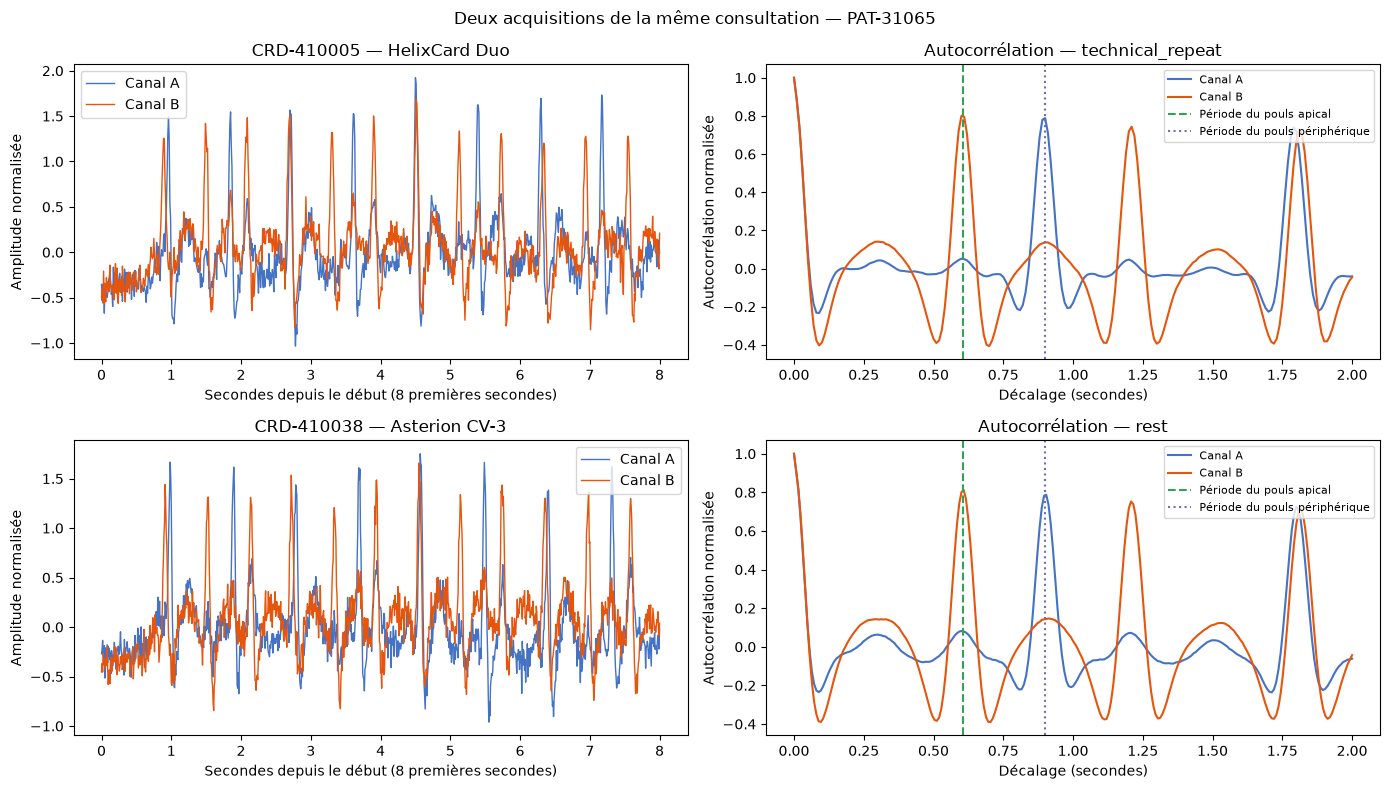

In [65]:
fig, axes = plt.subplots(len(signal_case), 2, figsize=(14, 4 * len(signal_case)), squeeze=False)
for row, (_, recording) in enumerate(signal_case.iterrows()):
    block = signal_samples[signal_samples["recording_id"].eq(recording["recording_id"])].sort_values("time_ms")
    visible = block[block["time_ms"] <= 8000]
    for channel, label, color in [
        ("channel_a_normalized", "Canal A", "#4472C4"),
        ("channel_b_normalized", "Canal B", "#E6550D")
    ]:
        axes[row, 0].plot(visible["time_ms"] / 1000, visible[channel], color=color, linewidth=1, label=label)
        lags, acf = signal_acfs[(recording["recording_id"], channel)]
        keep = lags <= 2
        axes[row, 1].plot(lags[keep], acf[keep], color=color, label=label)

    axes[row, 0].set_title(recording["recording_id"] + " — " + recording["device_model"])
    axes[row, 0].set_xlabel("Secondes depuis le début (8 premières secondes)")
    axes[row, 0].set_ylabel("Amplitude normalisée")
    axes[row, 0].legend()
    axes[row, 1].axvline(60 / recording["numeric_value_apical"], color="#31A354", linestyle="--", label="Période du pouls apical")
    axes[row, 1].axvline(60 / recording["numeric_value_peripheral"], color="#756BB1", linestyle=":", label="Période du pouls périphérique")
    axes[row, 1].set_title("Autocorrélation — " + recording["recording_context"])
    axes[row, 1].set_xlabel("Décalage (secondes)")
    axes[row, 1].set_ylabel("Autocorrélation normalisée")
    axes[row, 1].legend(fontsize=8)

fig.suptitle("Deux acquisitions de la même consultation — PAT-31065")
plt.tight_layout()
plt.savefig(OUT / "signaux_et_autocorrelation.png", dpi=150, bbox_inches="tight")
plt.show()

recording_audit.to_csv(OUT / "controle_enregistrements.csv", index=False)
recording_measures.to_csv(OUT / "enregistrements_et_mesures.csv", index=False)
signal_periods.to_csv(OUT / "periodes_signaux_exemple.csv", index=False)

**Résultats.** Les 44 enregistrements concernent 42 patients et 42 consultations. Les liens contrôlés sont cohérents. Les 96 925 lignes d'échantillons correspondent aux nombres annoncés ; les grilles de temps sont régulières et les deux canaux sont présents.

Pour `PAT-31065`, le canal A présente un motif autour de 66–67 cycles/min, proche du pouls périphérique de 66,8 bpm. Le canal B présente un motif autour de 99–100 cycles/min, proche du pouls apical de 99,2 bpm. On retrouve ces deux périodicités dans les deux acquisitions, avec des modèles d'appareil et des fréquences d'échantillonnage différents.

Cela décrit les signaux disponibles. L'heure exacte des acquisitions et les informations de calibration ne sont pas fournies. On ne peut pas certifier leur simultanéité avec les mesures ni valider un état médical à partir de ces rapprochements.

## 8. Notes cliniques et synthèse

On utilise les notes pour compléter le contexte des cas étudiés. On distingue les observations calculées, les hypothèses écrites dans les notes et les points restant à vérifier.

In [66]:
notes_raw = pd.read_csv(DATA / "health/clinical_notes.csv", dtype=str,
                        keep_default_na=False, na_values=[""])
notes = notes_raw.drop_duplicates().copy()
notes["document_date"] = pd.to_datetime(notes["document_date"], format="mixed", dayfirst=True, errors="coerce")
notes["text_readable"] = notes["text"].str.replace(r"\n", "\n", regex=False)

print("Notes :", len(notes))
print("Patients représentés :", notes["patient_number"].nunique())
print("Identifiants répétés :", int(notes["document_id"].duplicated().sum()))
print("Dates non converties :", int((notes_raw["document_date"].notna() & notes["document_date"].isna()).sum()))
print("Notes sans texte :", int(notes["text"].isna().sum()))
print("Remplacements de notes signalés :", int(notes["superseded_document_id"].notna().sum()))
notes.groupby("document_type").agg(notes=("document_id", "size"), patients=("patient_number", "nunique"))

Notes : 30
Patients représentés : 27
Identifiants répétés : 0
Dates non converties : 0
Notes sans texte : 0
Remplacements de notes signalés : 0


,notes,patients
document_type,,
clinical_summary,6,6
follow_up_note,6,6
imaging_report,6,6
occupational_assessment,6,6
specialist_consultation,6,6


### 8.1 Liens et dates des notes

On vérifie le patient et la consultation de chaque note. La date de rédaction est comparée au jour de la consultation. Une note rédigée plus tard ne correspond pas forcément à un nouvel événement médical.

In [67]:
notes_links = notes.merge(
    clean["encounters"][["encounter_number", "patient_number", "encounter_start", "facility_license_number"]],
    on="encounter_number", how="left", suffixes=("", "_consultation"),
    validate="many_to_one", indicator=True
)
known_note_encounter = notes_links["_merge"].eq("both")
notes_links["ecart_jours"] = (
    notes_links["document_date"].dt.normalize() - notes_links["encounter_start"].dt.normalize()
).dt.days
notes_before_encounter = notes_links[notes_links["ecart_jours"].lt(0)].copy()

pd.DataFrame({
    "contrôle": ["Patient introuvable", "Consultation introuvable", "Patient différent",
                 "Établissement différent", "Note datée avant la consultation"],
    "nombre": [
        int((~notes["patient_number"].isin(clean["patients"]["patient_number"])).sum()),
        int((~known_note_encounter).sum()),
        int((known_note_encounter & notes_links["patient_number"].ne(notes_links["patient_number_consultation"])).sum()),
        int((known_note_encounter & notes_links["facility_license_number"].ne(notes_links["facility_license_number_consultation"])).sum()),
        len(notes_before_encounter)
    ]
})

,contrôle,nombre
0,Patient introuvable,0
1,Consultation introuvable,0
2,Patient différent,0
3,Établissement différent,0
4,Note datée avant la consultation,8


In [68]:
notes_before_encounter[[
    "document_id", "patient_number", "encounter_number", "document_date", "encounter_start", "ecart_jours"
]].sort_values("ecart_jours")

,document_id,patient_number,encounter_number,document_date,encounter_start,ecart_jours
11,CLN-510129,PAT-31136,ENC-000105,2018-05-03,2021-10-03 09:15:00,-1249
19,CLN-510038,PAT-31169,ENC-000209,2018-09-05,2021-09-21 12:15:00,-1112
20,CLN-510058,PAT-31126,ENC-000222,2021-02-12,2022-02-13 10:15:00,-366
14,CLN-510118,PAT-31190,ENC-000144,2019-08-24,2020-08-18 12:15:00,-360
25,CLN-510093,PAT-31222,ENC-000287,2020-03-20,2021-02-15 11:15:00,-332
15,CLN-510039,PAT-31103,ENC-000157,2022-01-04,2022-11-21 12:15:00,-321
26,CLN-510036,PAT-31171,ENC-000300,2023-08-27,2024-01-28 11:15:00,-154
1,CLN-510055,PAT-31115,ENC-000016,2024-01-19,2024-04-03 13:15:00,-75


Les liens des 30 notes sont cohérents. Huit dates sont antérieures à la consultation référencée. On conserve les lignes en signalant les cas : les données seules ne permettent pas de choisir entre une date à corriger, une mauvaise référence de consultation ou une autre explication documentaire.

### 8.2 Lire les formulations dans leur contexte

La formulation `dual cardiac structures` apparaît dans deux notes. On affiche le paragraphe concerné pour vérifier si elle est retenue comme hypothèse ou rejetée.

In [69]:
PHRASE = "dual cardiac structures"
phrase_notes = notes[notes["text_readable"].str.contains(PHRASE, case=False, regex=False, na=False)]

for _, note in phrase_notes.iterrows():
    print(note["document_id"], "—", note["patient_number"], "—", note["title"])
    for paragraph in note["text_readable"].split("\n\n"):
        if PHRASE in paragraph.lower():
            print(paragraph)
    print()


CLN-510027 — PAT-31065 — Targeted Thoracic Imaging Review
IMPRESSION
Reproducible dual cardiac structures are considered as an imaging differential because two contractile sources are spatially separated and partly independent in timing. This wording describes the observed pattern rather than a final anatomical conclusion. Correlation with the paired signal recording, prior imaging, and specialist review is recommended.

CLN-510126 — PAT-31099 — Thoracic Imaging Report 07
DIFFERENTIAL NOTE
The phrase dual cardiac structures was entered in the preliminary worksheet but rejected after the apparent second contour disappeared on repeat positioning.



Dans `CLN-510027` pour `PAT-31065`, il s'agit d'une hypothèse d'imagerie à confronter aux autres examens. Les deux périodicités repérées au §7 vont dans le sens de rythmes différents dans les signaux, sans établir leur origine anatomique.

Dans `CLN-510126` pour `PAT-31099`, la même formulation a été rejetée après repositionnement. Compter les mots seuls aurait donc rapproché deux situations différentes.

### 8.3 Vérifier une attribution écrite dans une note

`CLN-510025` propose le lien entre `PAT-31065` et Elias Voss. Ce nom figure dans les mandats d'organisations, donc on consulte aussi `officer_filings.csv` pour comparer les éléments disponibles.

In [70]:
officers_context = pd.read_csv(DATA / "public_records/officer_filings.csv", dtype=str,
                              keep_default_na=False, na_values=[""])
elias_records = officers_context[
    officers_context["full_name"].str.contains(r"\bElias Voss\b", case=False, regex=True, na=False)
].copy()

print("Fiche patient citée dans la note")
display(clean["patients"].loc[
    clean["patients"]["patient_number"].eq("PAT-31065"),
    ["patient_number", "date_of_birth", "home_region", "occupation_text"]
])
print("Mention dans les mandats")
display(elias_records[[
    "filing_id", "full_name", "birth_year_or_age_band", "nationality_or_region", "role_title"
]])

Fiche patient citée dans la note


,patient_number,date_of_birth,home_region,occupation_text
6,PAT-31065,1975-10-09,Valenne Republic,clinical specialist


Mention dans les mandats


,filing_id,full_name,birth_year_or_age_band,nationality_or_region,role_title
3,FLG-000004,Dr. Elias Voss,1961,Valennan,Executive chair of Meridian BioLogistics


La fiche patient indique une naissance en **1975**, contre **1961** dans `FLG-000004` pour Elias Voss. Ce rapprochement n'est donc pas reproduit par nos critères de naissance.

On conserve l'attribution comme une affirmation de `CLN-510025`, à vérifier avec d'autres éléments. Elle n'est pas ajoutée aux correspondances probables du §6.

### 8.4 Résultats à retenir

La méthode suivie est : contrôler les fichiers, retirer les copies identiques, convertir les formats, décrire les patients, comparer les mesures, regrouper les profils et confronter les cas aux autres sources.

Les valeurs manquantes et les observations à vérifier ont été conservées. Les analyses se rejouent en exécutant les cellules dans l'ordre.

In [71]:
health_summary = pd.DataFrame([
    {"partie": "Qualité", "résultat": "6 copies identiques retirées ; dates et valeurs converties"},
    {"partie": "Patients", "résultat": f"{len(clean['patients'])} patients ; âge médian de {clean['patients']['age'].median():.0f} ans à la date de référence"},
    {"partie": "Pouls", "résultat": f"{len(pulse_comparison)} paires ; écart moyen de {pulse_comparison['difference'].mean():.2f} bpm"},
    {"partie": "Écarts de pouls", "résultat": f"{len(atypical_pulse)} paires repérées chez {atypical_pulse['patient_number'].nunique()} patients"},
    {"partie": "Interprétations", "résultat": f"{len(range_inconsistencies)} décalages entre valeur, intervalle et code d'interprétation"},
    {"partie": "Profils", "résultat": f"{chosen_k} groupes ; silhouette de {clustering_scores.loc[chosen_k, 'silhouette']:.3f}"},
    {"partie": "Procédures", "résultat": f"{len(procedures)} actes chez {procedures['patient_number'].nunique()} patients"},
    {"partie": "Registres", "résultat": f"{len(probable_matches)} correspondances probables, à confirmer"},
    {"partie": "Enregistrements", "résultat": f"{len(recordings)} enregistrements ; {len(signal_samples)} lignes d'échantillons cohérentes avec les métadonnées"},
    {"partie": "Notes", "résultat": f"{len(notes)} notes ; {len(notes_before_encounter)} dates antérieures à la consultation référencée"}
])
with pd.option_context("display.max_colwidth", 110):
    display(health_summary)

health_summary.to_csv(OUT / "resume_sante.csv", index=False)
notes_before_encounter[[
    "document_id", "patient_number", "encounter_number", "document_date", "encounter_start", "ecart_jours"
]].to_csv(OUT / "notes_dates_a_verifier.csv", index=False)

,partie,résultat
0,Qualité,6 copies identiques retirées ; dates et valeurs converties
1,Patients,240 patients ; âge médian de 54 ans à la date de référence
2,Pouls,1017 paires ; écart moyen de 3.96 bpm
3,Écarts de pouls,50 paires repérées chez 18 patients
4,Interprétations,"25 décalages entre valeur, intervalle et code d'interprétation"
5,Profils,3 groupes ; silhouette de 0.308
6,Procédures,310 actes chez 180 patients
7,Registres,"9 correspondances probables, à confirmer"
8,Enregistrements,44 enregistrements ; 96925 lignes d'échantillons cohérentes avec les métadonnées
9,Notes,30 notes ; 8 dates antérieures à la consultation référencée


### 8.5 Limites

- Les données sont fictives. Les valeurs atypiques et les signaux ne permettent pas de poser un diagnostic ou de déduire une anatomie.
- Les consultations sont répétées et irrégulières. Les résumés par patient masquent une partie de leur évolution.
- Les groupes dépendent des variables et des échelles choisies ; leur séparation reste modérée.
- Les rapprochements de personnes restent des hypothèses. Une affirmation dans une note ne remplace pas une vérification des données.
- Les heures exactes d'acquisition, la calibration des appareils et certaines explications documentaires manquent. Les notes et les mesures ne constituent pas forcément des preuves indépendantes.